# Study 1: the first gate (Grounding DINO) on LIBERO-Spatial

Code of **Section IV** of the paper (Tables II and III, Figs. 2 and 3). The gate sits in front of SmolVLA and decides, before any
motion, whether SmolVLA may act. Grounding uses Grounding DINO; the score is C = 0.27 G + 0.40 S + 0.33 D.

* **Development** = initial states 0-1 (140 cases), **test** = initial states 2-4 (210 cases: 90 impossible, 120 valid instructions).
* Weights, thresholds and the confidence ramp were chosen on development only and frozen (`frozen_config.json`, hash `a4a4d6846a`)
  before any test case was run.
* Every long cell is **resumable**: it appends to a CSV file and skips cases that are already saved. With the saved result files in
  `results/`, the run cells only print "0 to run" and the results cells print the tables in seconds.

*The printed output below each cell is the output of our own run (paths shortened). Long progress logs are shortened to their first and last lines.*

In [ ]:
# Shared set-up (about 3 min): result folders, models, simulator and the gate's code. Run it once per session.
%run -i setup/s0_paths.py
%run -i setup/s1_models_and_simulator.py
%run -i setup/s2_engine.py
%run -i setup/s3_calibrate_camera.py
%run -i setup/s4_engine_fixes.py
%run -i setup/s5_policy_helpers.py
%run -i setup/s6_study1_setup.py

## Task 1: SmolVLA baseline (10 tasks x 5 initial states, about 1.5-2 h, resumable)

In [ ]:
# ============================================================================
# TASK 1 — STRONG SmolVLA BASELINE: 10 tasks x 5 start states (0-4), no gate. RESUMABLE (stop/re-run any time).
# Records success, episode length, execution time and a failure reason. ~50 episodes, about 1.5-2 h.
# States 0-1 are re-run on purpose: their outcome must equal the old v2 baseline (reproducibility check).
# ============================================================================
BASE_FIELDS = ROLL_FIELDS
done = _done_keys(BASE_V4_CSV, ["task_id", "state"])
todo = [(t, s) for s in DEV_STATES + TEST_STATES for t in range(NUM_TASKS) if (str(t), str(s)) not in done]
print(f"baseline: {len(todo)} episodes to run ({len(done)} already saved)")
t_start = time.time()
for i, (t, s) in enumerate(todo):
    env, _, instr = get_task_env_and_instruction(t)
    row = run_baseline_v4(env, t, s, instr)
    env.close()
    _append(BASE_V4_CSV, BASE_FIELDS, row)
    eta = (time.time() - t_start) / (i + 1) * (len(todo) - i - 1) / 60
    print(f"[{i+1}/{len(todo)}] task {t} state {s}: success={row['success']} len={row['episode_length']} "
          f"{row['failure_reason']} ({row['execution_time']}s, ~{eta:.0f} min left)")
print("TASK 1 RUN DONE")

baseline: 0 episodes to run (50 already saved)
TASK 1 RUN DONE


### Task 1: summary

In [ ]:
# ============================================================================
# TASK 1 — summary table (seconds)
# ============================================================================
b = pd.read_csv(BASE_V4_CSV).drop_duplicates(["task_id", "state"], keep="last")
print(f"SmolVLA clean baseline: {len(b)} episodes, success {b.success.mean():.1%} "
      f"(95% CI {wilson(int(b.success.sum()), len(b))}), mean length {b.episode_length.mean():.0f} steps, "
      f"mean time {b.execution_time.mean():.0f} s")
print("\nby split:")
print(b.groupby("split").agg(N=("success", "size"), success=("success", "mean"), length=("episode_length", "mean"),
                             time_s=("execution_time", "mean")).round(3).to_string())
print("\nby start state:")
print(b.groupby("state").success.mean().round(2).to_string())
print("\nby task (success over 5 states):")
print(b.groupby("task_id").success.mean().round(2).to_string())
print("\nfailure reasons:")
print(b[b.success == 0].failure_reason.value_counts().to_string())
try:
    old = pd.read_csv(BASELINE_CLEAN_CSV).drop_duplicates(["task_id", "episode_id"], keep="last")
    m = b.merge(old[["task_id", "episode_id", "success"]], left_on=["task_id", "state"], right_on=["task_id", "episode_id"],
                suffixes=("", "_old"))
    print(f"\nreproducibility check vs old v2 baseline (states 0-1): {int((m.success == m.success_old).sum())}/{len(m)} identical outcomes")
except Exception as e:
    print("old baseline not found:", e)
b.to_csv(os.path.join(V4_TAB, "task1_baseline.csv"), index=False)

SmolVLA clean baseline: 50 episodes, success 66.0% (95% CI (52.2, 77.6)), mean length 145 steps, mean time 102 s

by split:
        N  success   length   time_s
split                               
dev    20    0.650  146.550  103.523
test   30    0.667  144.733  101.089

by start state:
state
0    0.9
1    0.4
2    0.8
3    0.7
4    0.5

by task (success over 5 states):
task_id
0    0.4
1    1.0
2    0.6
3    1.0
4    0.6
5    0.2
6    0.4
7    0.8
8    0.6
9    1.0

failure reasons:
failure_reason
reached_but_no_grasp      9
grasped_but_not_placed    7
never_reached_target      1

reproducibility check vs old v2 baseline (states 0-1): 20/20 identical outcomes


## Task 2: verification sweep on the development split (140 cases, about 30 min, resumable)
Both grounding passes are logged for every case, so any weighting or threshold can be evaluated offline.

In [ ]:
# ============================================================================
# TASK 2 — DEVELOPMENT verification sweep: dev states x 10 tasks x 7 conditions = 140 cases. RESUMABLE.
# Logs BOTH the first grounding and the one re-grounding pass for every case, so any evidence formulation /
# threshold can be evaluated offline (Tasks 3-5) without touching the test states. ~25-35 min.
# ============================================================================
if os.path.exists(FROZEN_JSON):
    print("NOTE: a frozen config already exists - the development sweep is only being completed, not re-tuned.")
run_verification(DEV_STATES)
OBS_HOOK = None
print("TASK 2 DEV SWEEP DONE")

NOTE: a frozen config already exists - the development sweep is only being completed, not re-tuned.
verification: 0 cases to run (350 already saved)
TASK 2 DEV SWEEP DONE


## Tasks 3-5: grounding check, ablation, and the FREEZE (development only, seconds)
A predefined grid of 45 configurations is evaluated on development; the best by J = invalid refused + valid accepted - 1 is written to `frozen_config.json`. An existing file is never overwritten.

In [ ]:
# ============================================================================
# TASKS 3, 4, 5 on the DEVELOPMENT set only (seconds): grounding validation, component ablation,
# evidence formulation + thresholds chosen from a small PREDEFINED grid, then FROZEN to frozen_config.json.
# ============================================================================
dev = load_verify("dev")
cands = load_cands()
bsm = base_success_map()
print(f"development cases: {len(dev)} (expected {len(DEV_STATES) * NUM_TASKS * len(KINDS)})")

# sanity check: the offline recomputation reproduces the engine's own G/S/D at the default calibration
_chk = [abs(scene_vals(r, "0", (0.22, 0.40))["G"] - float(r["G_0"])) + abs(scene_vals(r, "0", (0.22, 0.40))["S"] - float(r["S_0"]))
        for r in dev.to_dict("records")]
print(f"offline recomputation check: max |dG|+|dS| = {max(_chk):.4f} (should be ~0)")

# ---------------- TASK 3: grounding validation (independent of the gate) ----------------
def grounding_table(df, sfx):
    rows = []
    for kind in VALID_KINDS + ["relation_violation"]:
        g = df[df.kind == kind]
        rt = pd.to_numeric(g[f"right_target_{sfx}"], errors="coerce")
        rr = pd.to_numeric(g[f"right_ref_{sfx}"], errors="coerce")
        joint = [int(t == 1 and (r == 1 or r != r)) for t, r in zip(rt, rr)]
        rows.append({"condition": kind, "N": len(g), "target acc %": pct(rt.mean()),
                     "reference acc %": pct(rr.dropna().mean()) if rr.notna().any() else float("nan"),
                     "joint acc %": pct(np.mean(joint)) if len(joint) else float("nan"),
                     "goal acc %": pct(pd.to_numeric(g[f"right_goal_{sfx}"], errors="coerce").mean()),
                     "picked other bowl %": pct((g[f"sel_{sfx}"] == "other_bowl").mean()),
                     "no/other object %": pct(g[f"sel_{sfx}"].isin(["none", "not_a_bowl"]).mean())})
    return pd.DataFrame(rows)

gt0 = grounding_table(dev, "0")
print("\nTASK 3 - grounding accuracy (development, first grounding pass):")
print(gt0.to_string(index=False))
print("\n(after the re-grounding pass):")
print(grounding_table(dev, "1").to_string(index=False))
gt0.to_csv(os.path.join(V4_TAB, "task3_grounding_dev.csv"), index=False)

# ---------------- TASK 4: evidence components (selection + decision) ----------------
def selection_accuracy(df, rule):
    """which bowl would each evidence set pick? G: most confident; G+S: best 2D relation; G+S+D: 2D+3D (the method)."""
    hits = []
    for r in df[df.kind.isin(VALID_KINDS)].itertuples():
        c = cands.get((int(r.task_id), int(r.state), r.kind), {}).get("cands_0", [])
        if not c:
            hits.append(0); continue
        if rule == "G":
            best = max(c, key=lambda x: x["conf"])
        elif rule == "G+S":
            best = max(c, key=lambda x: (x["s"], x["conf"]))
        else:
            best = max(c, key=lambda x: x["rel"] + 0.05 * ramp_up(x["conf"], 0.22, 0.40))
        hits.append(best["right"])
    return pct(np.mean(hits)) if hits else float("nan")

def renorm(w):
    s = sum(w)
    return tuple(x / s for x in w)

ABL = [("+G", (1, 0, 0, 0), "G"), ("+G+S", renorm((0.20, 0.30, 0, 0)), "G+S"),
       ("+G+S+D", renorm((0.20, 0.30, 0.25, 0)), "G+S+D"), ("+G+S+D+A", (0.20, 0.30, 0.25, 0.25), "G+S+D")]
abl_rows = [{"config": "SmolVLA only", "selection acc %": "-", "IER %": 100.0, "valid_accept %": 100.0,
             "valid_abstain %": 0.0, "clean_TSR %": pct(np.mean([bsm[(int(r.task_id), int(r.state))]
                                                                 for r in dev[dev.kind == "clean"].itertuples()])), "AUROC(C)": "-"}]
for name, w, rule in ABL:
    cfg = {**CURRENT_CFG, "weights": w}
    s = summarize(decide_all(dev, cfg), bsm)
    abl_rows.append({"config": name, "selection acc %": selection_accuracy(dev, rule), "IER %": s["IER %"],
                     "valid_accept %": s["valid_accept %"], "valid_abstain %": s["valid_abstain %"],
                     "clean_TSR %": s.get("clean_TSR %"), "AUROC(C)": s["AUROC(C)"]})
abl_dev = pd.DataFrame(abl_rows)
print("\nTASK 4 - evidence components (development; complete gate logic, current thresholds 0.75/0.50):")
print(abl_dev.to_string(index=False))
abl_dev.to_csv(os.path.join(V4_TAB, "task4_components_dev.csv"), index=False)

# ---------------- TASK 5: small PREDEFINED grid, chosen on development only ----------------
FORMULATIONS = {"GSDA (v3)": (0.20, 0.30, 0.25, 0.25),
                "GSD (A removed)": renorm((0.20, 0.30, 0.25, 0.0)),
                "GSD equal": (1 / 3, 1 / 3, 1 / 3, 0.0)}
RAMPS = [(0.22, 0.40), (0.22, 0.35), (0.25, 0.45)]
THRESHOLDS = [(0.75, 0.50), (0.70, 0.50), (0.75, 0.45), (0.80, 0.55), (0.70, 0.45)]
# selection rule fixed BEFORE looking at the grid: maximise J = (invalid refused) + (valid accepted) - 1 (Youden);
# ties -> higher clean TSR -> higher AUROC -> closest to the v3 defaults.
grid = []
for (fname, w), ramp, (hi, lo) in itertools.product(FORMULATIONS.items(), RAMPS, THRESHOLDS):
    cfg = {**CURRENT_CFG, "name": fname, "weights": w, "ramp": ramp, "high": hi, "low": lo}
    s = summarize(decide_all(dev, cfg), bsm)
    dist = abs(hi - 0.75) + abs(lo - 0.50) + abs(ramp[0] - 0.22) + abs(ramp[1] - 0.40)
    grid.append({"formulation": fname, "ramp": f"{ramp[0]:.2f}-{ramp[1]:.2f}", "high": hi, "low": lo, **s, "_dist": dist, "_cfg": cfg})
grid_df = pd.DataFrame(grid)
grid_df = grid_df.sort_values(["J", "clean_TSR %", "AUROC(C)", "_dist"], ascending=[False, False, False, True])
print("\nTASK 5 - top 10 of the predefined grid (development):")
print(grid_df.drop(columns=["_cfg", "_dist"]).head(10).to_string(index=False))
grid_df.drop(columns=["_cfg"]).to_csv(os.path.join(V4_TAB, "task5_grid_dev.csv"), index=False)

# does the action-consistency term help? same ramp + thresholds, with vs without A
cmp = []
for ramp, (hi, lo) in itertools.product(RAMPS, THRESHOLDS):
    rk = f"{ramp[0]:.2f}-{ramp[1]:.2f}"
    a = grid_df[(grid_df.formulation == "GSDA (v3)") & (grid_df.ramp == rk) & (grid_df.high == hi) & (grid_df.low == lo)].iloc[0]
    n = grid_df[(grid_df.formulation == "GSD (A removed)") & (grid_df.ramp == rk) & (grid_df.high == hi) & (grid_df.low == lo)].iloc[0]
    cmp.append({"ramp": rk, "high": hi, "low": lo, "J with A": a.J, "J without A": n.J,
                "AUROC with A": a["AUROC(C)"], "AUROC without A": n["AUROC(C)"]})
cmp = pd.DataFrame(cmp)
worse = int((cmp["J without A"] >= cmp["J with A"]).sum())
print(f"\naction-consistency check: removing A gives equal or better J in {worse}/{len(cmp)} settings; "
      f"mean AUROC with A {cmp['AUROC with A'].mean():.3f} vs without {cmp['AUROC without A'].mean():.3f}")
A_HURTS = worse >= 0.8 * len(cmp) and cmp["AUROC without A"].mean() >= cmp["AUROC with A"].mean()
print("=> A", "HURTS consistently -> removed from the final method" if A_HURTS else "does not consistently hurt -> kept")
cmp.to_csv(os.path.join(V4_TAB, "task5_action_term_dev.csv"), index=False)

best = grid_df.iloc[0]
if A_HURTS and best.formulation == "GSDA (v3)":
    best = grid_df[grid_df.formulation != "GSDA (v3)"].iloc[0]
if not A_HURTS and best.formulation != "GSDA (v3)":
    pass                                                    # the objective itself preferred a formulation without A
FINAL = {**best["_cfg"], "weights": [round(x, 6) for x in best["_cfg"]["weights"]], "ramp": list(best["_cfg"]["ramp"]),
         "name": f"v4 final ({best.formulation})", "selected_on": f"development start states {DEV_STATES}",
         "objective": "max J = invalid refused + valid accepted - 1; ties: clean TSR, AUROC, closeness to v3",
         "action_term_removed": bool(best["_cfg"]["weights"][3] == 0),
         "dev_metrics": {k: best[k] for k in ["IER %", "valid_accept %", "valid_abstain %", "AUROC(C)", "J", "clean_TSR %"] if k in best},
         "frozen_at": time.strftime("%Y-%m-%d %H:%M:%S")}
print("\nFINAL (to be frozen):", json.dumps(FINAL, indent=1, default=float))

# ---------------- FREEZE ----------------
if os.path.exists(FROZEN_JSON):
    print("\nfrozen_config.json ALREADY EXISTS - it is NOT overwritten (delete it by hand only if you really mean to re-tune).")
    print(open(FROZEN_JSON).read())
else:
    with open(FROZEN_JSON, "w") as f:
        json.dump(FINAL, f, indent=1, default=float)
    print("\nFROZEN ->", FROZEN_JSON)

development cases: 140 (expected 140)
offline recomputation check: max |dG|+|dS| = 0.0001 (should be ~0)

TASK 3 - grounding accuracy (development, first grounding pass):
         condition  N  target acc %  reference acc %  joint acc %  goal acc %  picked other bowl %  no/other object %
             clean 20          30.0             58.3         30.0       100.0                 70.0                0.0
        distractor 20          40.0             58.3         40.0       100.0                 30.0               30.0
   position_change 20          30.0             58.3         30.0        70.0                 55.0               15.0
         occlusion 20          15.0             25.0          0.0       100.0                 85.0                0.0
relation_violation 20          25.0             58.3         20.0       100.0                 60.0               15.0

(after the re-grounding pass):
         condition  N  target acc %  reference acc %  joint acc %  goal acc %  picked oth

## Tasks 7-8: verification sweep on the test split (210 cases, about 45 min, resumable)
Refuses to start before the configuration is frozen.

In [ ]:
# ============================================================================
# TASKS 7-8 — TEST verification sweep: test states x 10 tasks x 7 conditions = 210 cases. RESUMABLE. ~40-50 min.
# Refuses to run until the configuration has been frozen on the development set.
# ============================================================================
assert os.path.exists(FROZEN_JSON), "Run the Tasks 3-5 cell first: the configuration must be frozen before any test data is touched."
FROZEN = json.load(open(FROZEN_JSON))
FROZEN_HASH = hashlib.sha1(json.dumps(FROZEN, sort_keys=True, default=float).encode()).hexdigest()[:10]
print("frozen config:", FROZEN["name"], "| hash", FROZEN_HASH)
run_verification(TEST_STATES, FROZEN_HASH)
OBS_HOOK = None
print("TASK 7 TEST SWEEP DONE")

frozen config: v4 final (GSD (A removed)) | hash a4a4d6846a
verification: 210 cases to run (140 already saved)
[1/210] t0 s2 clean              G=0.96 S_rel=0.09 D_rel=0.36 sel=other_bowl (10.59s, ~37 min left)
[2/210] t0 s2 absent_reference   G=0.00 S_rel=0.00 D_rel=0.00 sel=other_bowl (10.8s, ~37 min left)
... (205 more lines of progress) ...
[208/210] t9 s4 distractor         G=1.00 S_rel=1.00 D_rel=0.89 sel=target     (13.25s, ~0 min left)
[209/210] t9 s4 position_change    G=1.00 S_rel=1.00 D_rel=0.95 sel=target     (13.13s, ~0 min left)
[210/210] t9 s4 occlusion          G=1.00 S_rel=0.00 D_rel=0.00 sel=other_bowl (13.3s, ~0 min left)
TASK 7 TEST SWEEP DONE


## Task 9: SmolVLA rollouts of the valid perturbed test cases (resumable)
The gate never changes SmolVLA's actions, so an accepted case has exactly the outcome of this rollout.

In [ ]:
# ============================================================================
# TASK 9 — ROLL OUT the valid perturbed TEST scenes with SmolVLA (the gate never changes SmolVLA's actions,
# so an ACCEPTED case's outcome is exactly this rollout). RESUMABLE, accepted cases first.
#   priority 1: valid perturbed cases the frozen gate ACCEPTS   (needed for "success given acceptance")
#   priority 2: valid perturbed cases the gate REFUSES          (SmolVLA's own success under perturbation)
#   priority 3 (optional): invalid cases, to show what SmolVLA physically does with a false instruction
# About 2 min per episode; priority 1 alone is roughly 1-1.5 h.
# ============================================================================
ROLL_INVALID = False           # set True for priority 3 (another ~3 h)
FROZEN = json.load(open(FROZEN_JSON))
test = decide_all(load_verify("test"), {**FROZEN, "weights": tuple(FROZEN["weights"]), "ramp": tuple(FROZEN["ramp"])})
q1 = test[test.kind.isin(VALID_PERTURBED) & (test.executed == 1)]
q2 = test[test.kind.isin(VALID_PERTURBED) & (test.executed == 0)]
q3 = test[test.kind.isin(INVALID_KINDS_V4)] if ROLL_INVALID else test.iloc[0:0]
queue = pd.concat([q1, q2, q3])
done = _done_keys(ROLL_CSV, ["task_id", "state", "condition"])
queue = [r for r in queue.itertuples() if (str(r.task_id), str(r.state), r.kind) not in done]
print(f"rollouts to run: {len(queue)} (accepted valid first: {len(q1)} | refused valid: {len(q2)} | invalid: {len(q3)}; "
      f"{len(done)} already saved)")
t_start = time.time()
for i, r in enumerate(queue):
    env, _, _ = get_task_env_and_instruction(int(r.task_id))
    row = run_baseline_v4(env, int(r.task_id), int(r.state), r.instruction,
                          perturb=r.kind if r.kind in SCENE_PERTURBATIONS else None)
    env.close()
    OBS_HOOK = None
    row["condition"] = r.kind
    _append(ROLL_CSV, ROLL_FIELDS, row)
    eta = (time.time() - t_start) / (i + 1) * (len(queue) - i - 1) / 60
    print(f"[{i+1}/{len(queue)}] t{r.task_id} s{r.state} {r.kind:16s} gate={r.decision:8s} SmolVLA success={row['success']} "
          f"{row['failure_reason']} (~{eta:.0f} min left)")
print("TASK 9 ROLLOUTS DONE")

rollouts to run: 90 (accepted valid first: 34 | refused valid: 56 | invalid: 0; 0 already saved)
[1/90] t1 s2 position_change  gate=EXECUTE  SmolVLA success=0 grasped_but_not_placed (~249 min left)
[2/90] t3 s2 position_change  gate=EXECUTE  SmolVLA success=0 grasped_but_not_placed (~242 min left)
[3/90] t3 s2 occlusion        gate=EXECUTE  SmolVLA success=0 grasped_but_not_placed (~238 min left)
... (84 more lines of progress) ...
[88/90] t8 s4 position_change  gate=ABSTAIN  SmolVLA success=0 never_reached_target (~5 min left)
[89/90] t8 s4 occlusion        gate=ABSTAIN  SmolVLA success=0 never_reached_target (~2 min left)
[90/90] t9 s4 occlusion        gate=ABSTAIN  SmolVLA success=0 grasped_but_not_placed (~0 min left)
TASK 9 ROLLOUTS DONE


## Final test results (Table II, re-grounding, ablation, grounding accuracy, failure analysis)

In [ ]:
# ============================================================================
# TASKS 6, 8, 9, 10 — FINAL TEST RESULTS with the frozen configuration (seconds).
# ============================================================================
FROZEN = json.load(open(FROZEN_JSON))
FCFG = {**FROZEN, "weights": tuple(FROZEN["weights"]), "ramp": tuple(FROZEN["ramp"])}
bsm = base_success_map()
cands = load_cands()
test = decide_all(load_verify("test"), FCFG)
roll = pd.read_csv(ROLL_CSV).drop_duplicates(["task_id", "state", "condition"], keep="last") if os.path.exists(ROLL_CSV) else pd.DataFrame(columns=ROLL_FIELDS)
rsm = {(int(r.task_id), int(r.state), r.condition): int(r.success) for r in roll.itertuples()}

def smol_success(r):
    if r.kind == "clean":
        return bsm.get((int(r.task_id), int(r.state)))
    return rsm.get((int(r.task_id), int(r.state), r.kind))

test["smolvla_success"] = [smol_success(r) for r in test.itertuples()]
print(f"test cases: {len(test)} | frozen config: {FROZEN['name']} weights={FROZEN['weights']} "
      f"thresholds={FROZEN['high']}/{FROZEN['low']} ramp={FROZEN['ramp']}")

# ---------------- main table (Tasks 8-9) ----------------
rows = []
for kind in KINDS:
    g = test[test.kind == kind]
    n = len(g)
    valid = kind in VALID_KINDS
    acc = int(g.executed.sum())
    row = {"condition": kind, "N": n, "gate accept %": pct(acc / n) if n else float("nan"),
           "gate accept 95% CI": wilson(acc, n), "RR %": pct(g.initial_band.mean()),
           "gate overhead s": round(float((g.t_perceive0_s + g.t_perceive1_s * g.reground_used).mean()), 2)}
    if valid:
        s = g.smolvla_success
        known = s.notna()
        row["SmolVLA TSR %"] = pct(s[known].mean()) if known.any() else float("nan")
        sa = g[(g.executed == 1) & known]
        row["success | accepted %"] = pct(sa.smolvla_success.mean()) if len(sa) else float("nan")
        row["gate TSR %"] = pct((g.executed * s.fillna(0))[known].mean()) if known.any() else float("nan")
        row["rolled out"] = f"{int(known.sum())}/{n}"
        row["SmolVLA IER %"], row["gate IER %"] = "-", "-"
    else:
        row["SmolVLA IER %"], row["gate IER %"] = 100.0, (pct(acc / n) if n else float("nan"))
    rows.append(row)
main = pd.DataFrame(rows)
print("\nMAIN TABLE (test set):")
print(main.to_string(index=False))
main.to_csv(os.path.join(V4_TAB, "main_test.csv"), index=False)

inv = test[test.valid == 0]
k_inv = int(inv.executed.sum())
print(f"\nIER overall: SmolVLA 100% vs gate {pct(k_inv / len(inv))}% (95% CI {wilson(k_inv, len(inv))}), "
      f"exact McNemar p = {mcnemar_exact(len(inv) - k_inv, 0):.2e}")
cl = test[(test.kind == "clean") & test.smolvla_success.notna()]
lost = int(((cl.smolvla_success == 1) & (cl.executed == 0)).sum()); gained = 0
print(f"clean TSR: SmolVLA {pct(cl.smolvla_success.mean())}% vs gate {pct((cl.smolvla_success * cl.executed).mean())}% "
      f"(lost {lost}, exact McNemar p = {mcnemar_exact(lost, gained):.3f})")
print(f"AUROC of C (valid vs invalid): {auroc(test[test.valid == 1].C, test[test.valid == 0].C):.3f}")
lu = test[test.label_uncertain == 1]
print(f"label-uncertain valid cases (plate is a reference and was moved, or distractor with 'next to'): {len(lu)} "
      f"-> accepted {int(lu.executed.sum())}")
print(f"mean SmolVLA first-inference time {test.t_policy_s.mean():.2f} s | mean gate overhead "
      f"{(test.t_perceive0_s + test.t_perceive1_s * test.reground_used).mean():.2f} s per episode")

# ---------------- Task 6: re-grounding ----------------
no_rg = decide_all(load_verify("test"), {**FCFG, "reground": False})
m6 = test[["task_id", "state", "kind", "valid", "executed", "smolvla_success"]].merge(
    no_rg[["task_id", "state", "kind", "executed"]], on=["task_id", "state", "kind"], suffixes=("", "_noRG"))
trig = int(test.reground_used.sum())
rec_valid = m6[(m6.valid == 1) & (m6.executed_noRG == 0) & (m6.executed == 1)]
prev_inv = m6[(m6.valid == 0) & (m6.executed_noRG == 1) & (m6.executed == 0)]
lost_valid = m6[(m6.valid == 1) & (m6.executed_noRG == 1) & (m6.executed == 0)]
new_inv = m6[(m6.valid == 0) & (m6.executed_noRG == 0) & (m6.executed == 1)]
lifted = int(((test.reground_used == 1) & (test.scene_used == "1")).sum())
print(f"\nTASK 6 - re-grounding: triggered in {trig}/{len(test)} cases; the re-grounded scene was better in {lifted}. "
      f"Recovered valid cases: {len(rec_valid)} (of which succeeded: {int(rec_valid.smolvla_success.fillna(0).sum())}); "
      f"prevented invalid executions: {len(prev_inv)}; valid cases lost: {len(lost_valid)}; invalid cases newly executed: {len(new_inv)}")

# ---------------- Task 10: final ablation on test ----------------
def sel_acc(df, rule):
    hits = []
    for r in df[df.kind.isin(VALID_KINDS)].itertuples():
        c = cands.get((int(r.task_id), int(r.state), r.kind), {}).get("cands_0", [])
        if not c:
            hits.append(0); continue
        best = (max(c, key=lambda x: x["conf"]) if rule == "G" else
                max(c, key=lambda x: (x["s"], x["conf"])) if rule == "G+S" else
                max(c, key=lambda x: x["rel"] + 0.05 * ramp_up(x["conf"], 0.22, 0.40)))
        hits.append(best["right"])
    return pct(np.mean(hits)) if hits else float("nan")

def renorm(w):
    s = sum(w)
    return tuple(x / s for x in w)

tv = load_verify("test")
abl = [{"config": "SmolVLA only", "selection acc %": "-", "IER %": 100.0, "valid accept %": 100.0,
        "clean TSR %": pct(cl.smolvla_success.mean()), "AUROC": "-"}]
for name, w, rule in [("+G", (1, 0, 0, 0), "G"), ("+G+S", renorm((0.20, 0.30, 0, 0)), "G+S"),
                      ("+G+S+D", renorm((0.20, 0.30, 0.25, 0)), "G+S+D")]:
    s = summarize(decide_all(tv, {**FCFG, "weights": w}), bsm)
    abl.append({"config": name, "selection acc %": sel_acc(tv, rule), "IER %": s["IER %"], "valid accept %": s["valid_accept %"],
                "clean TSR %": s.get("clean_TSR %"), "AUROC": s["AUROC(C)"]})
s = summarize(test, bsm)
abl.append({"config": f"final gate ({FROZEN['name']})", "selection acc %": sel_acc(tv, "G+S+D"), "IER %": s["IER %"],
            "valid accept %": s["valid_accept %"], "clean TSR %": s.get("clean_TSR %"), "AUROC": s["AUROC(C)"]})
abl = pd.DataFrame(abl)
print("\nTASK 10 - ablation (test set, frozen thresholds):")
print(abl.to_string(index=False))
abl.to_csv(os.path.join(V4_TAB, "ablation_test.csv"), index=False)

# ---------------- Task 3 on test ----------------
print("\nTASK 3 - grounding accuracy (test, first grounding pass):")
def grounding_table_t(df, sfx):
    rows = []
    for kind in VALID_KINDS + ["relation_violation"]:
        g = df[df.kind == kind]
        rt = pd.to_numeric(g[f"right_target_{sfx}"], errors="coerce")
        rr = pd.to_numeric(g[f"right_ref_{sfx}"], errors="coerce")
        joint = [int(t == 1 and (r == 1 or r != r)) for t, r in zip(rt, rr)]
        rows.append({"condition": kind, "N": len(g), "target acc %": pct(rt.mean()),
                     "reference acc %": pct(rr.dropna().mean()) if rr.notna().any() else float("nan"),
                     "joint acc %": pct(np.mean(joint)) if joint else float("nan")})
    return pd.DataFrame(rows)
g3 = grounding_table_t(tv, "0")
print(g3.to_string(index=False))
g3.to_csv(os.path.join(V4_TAB, "task3_grounding_test.csv"), index=False)

# ---------------- Task 10: failure analysis (one uniform rule set) ----------------
def classify(r):
    sfx = r.scene_used
    v = scene_vals(r._asdict(), sfx, tuple(FCFG["ramp"]))
    rt = _num(getattr(r, f"right_target_{sfx}"))
    rr = _num(getattr(r, f"right_ref_{sfx}"))
    sel = getattr(r, f"sel_{sfx}")
    grounded_ok = (rt in (1.0, None)) and (rr in (1.0, None)) and sel in ("target", "other_bowl")
    if r.valid == 0 and r.executed == 1:                                   # acted on an invalid instruction
        if r.kind in ("absent_reference", "absent_target"):
            return "grounding (absent object detected)"
        if not ((rr in (1.0, None)) and sel in ("target", "other_bowl")):
            return "grounding"
        if v["D_rel"] >= 0.5:
            return "depth / 3D"
        if v["S_rel"] >= 0.5:
            return "spatial relation"
        return "threshold / calibration"
    if r.valid == 1 and r.executed == 0:                                   # refused a valid instruction
        if r.label_uncertain == 1:
            return "label uncertain (not counted)"
        if not grounded_ok or sel != "target":
            return "grounding"
        if v["S_rel"] < 0.3:
            return "spatial relation"
        if v["D_rel"] < 0.3:
            return "depth / 3D"
        return "threshold / calibration"
    if r.valid == 1 and r.executed == 1 and r.smolvla_success == 0:        # accepted, then SmolVLA failed
        return "action / execution"
    return None

test["failure"] = [classify(r) for r in test.itertuples()]
fails = test[test.failure.notna()]
fa = fails.failure.value_counts().rename_axis("cause").reset_index(name="count")
fa["share %"] = (100 * fa["count"] / fa["count"].sum()).round(1)
print("\nTASK 10 - failure analysis (test):")
print(fa.to_string(index=False))
print("\nby condition:")
print(pd.crosstab(fails.kind, fails.failure).to_string())
fa.to_csv(os.path.join(V4_TAB, "failures_test.csv"), index=False)
test.drop(columns=[c for c in test.columns if c.startswith("ref_confs")]).to_csv(os.path.join(V4_TAB, "test_decisions.csv"), index=False)

# accepted with the wrong bowl verified (right for the wrong reason)
acc_valid = test[(test.valid == 1) & (test.executed == 1)]
wrong = acc_valid[[getattr(r, f"sel_{r.scene_used}") != "target" for r in acc_valid.itertuples()]]
print(f"\naccepted valid cases verified on the wrong bowl: {len(wrong)}/{len(acc_valid)}")
print("\nALL RESULTS SAVED IN", V4_TAB)

test cases: 210 | frozen config: v4 final (GSD (A removed)) weights=[0.266667, 0.4, 0.333333, 0.0] thresholds=0.7/0.5 ramp=[0.22, 0.4]

MAIN TABLE (test set):
         condition  N  gate accept % gate accept 95% CI  RR %  gate overhead s  SmolVLA TSR %  success | accepted %  gate TSR % rolled out SmolVLA IER % gate IER %
             clean 30           60.0       (42.3, 75.4)   6.7             2.18           66.7                  72.2        43.3      30/30             -          -
  absent_reference 30            3.3        (0.6, 16.7)   3.3             3.99            NaN                   NaN         NaN        NaN         100.0        3.3
     absent_target 30           13.3        (5.3, 29.7)  13.3             3.44            NaN                   NaN         NaN        NaN         100.0       13.3
relation_violation 30           20.0        (9.5, 37.3)   6.7             3.38            NaN                   NaN         NaN        NaN         100.0       20.0
        distractor 30

## Figures from the result files (seconds)
Saved to `results/v4/paper_figures/`.

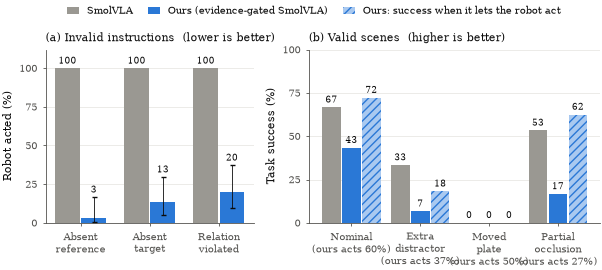

saved results/v4/paper_figures/fig_main_results.pdf / .png


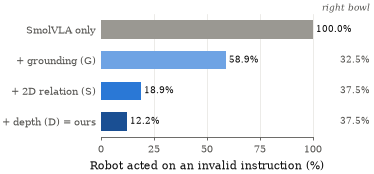

saved results/v4/paper_figures/fig_ablation.pdf / .png


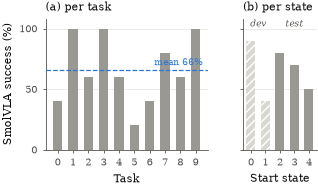

saved results/v4/paper_figures/fig_baseline.pdf / .png


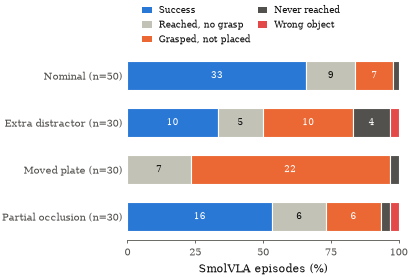

saved results/v4/paper_figures/fig_outcomes.pdf / .png


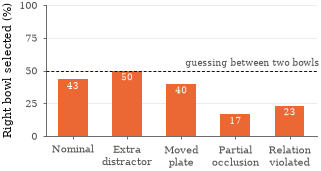

saved results/v4/paper_figures/fig_grounding.pdf / .png


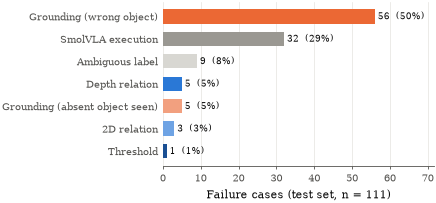

saved results/v4/paper_figures/fig_failures.pdf / .png


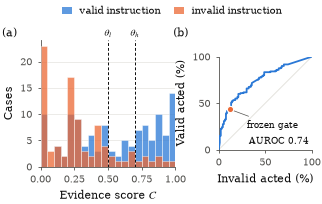

saved results/v4/paper_figures/fig_scores.pdf / .png

ALL PAPER FIGURES -> results/v4/paper_figures


In [ ]:
# %% CELL v4_paper_figures
# ============================================================================
# PAPER FIGURES (v4) — draws every results figure for the IEEE paper from the v4 result files. Takes seconds.
# Run AFTER the "v4 setup" cell (and after Tasks 1-9 have produced their files).
# Output: results/v4/paper_figures/  ->  each figure as .pdf (for the paper) and .png (300 dpi, for Word)
#   fig_main_results    SmolVLA vs ours: wrong instructions (robot acted) + valid scenes (task success)
#   fig_ablation        what each evidence term adds (wrong-action rate, right-bowl choice)
#   fig_baseline        SmolVLA alone: success per task and per start state (development vs test)
#   fig_outcomes        how SmolVLA ends each episode, per scene condition (shows the moved-plate failure)
#   fig_grounding       how often the detector picks the right bowl, per condition (vs. 50% guessing)
#   fig_failures        where the remaining errors come from (failure taxonomy)
#   fig_scores          evidence score C for valid vs invalid instructions + ROC curve
# ============================================================================
import os, math, logging
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

# ---------------- style: IEEE column = 3.5 in, full page width = 7.16 in, 8 pt serif ----------------
COL_W, FULL_W = 3.5, 7.16
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "Liberation Serif", "Nimbus Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix", "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "xtick.labelsize": 7,
    "ytick.labelsize": 7, "legend.fontsize": 7, "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5,
    "ytick.major.size": 2.5, "axes.edgecolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b", "legend.frameon": False, "savefig.dpi": 300,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.02, "pdf.fonttype": 42, "ps.fonttype": 42})
C_SMOL = "#9a9892"      # SmolVLA alone (neutral gray)
C_OURS = "#2a78d6"      # ours (blue)
C_DET = "#eb6834"       # detector-related (orange)
C_GRID = "#e4e3de"
C_MUTED = "#52514e"
BLUE_STEPS = ["#a9c9f0", "#6ea3e4", "#2a78d6", "#1a4f93"]   # light -> dark as evidence is added

COND = {"clean": "Nominal", "absent_reference": "Absent\nreference", "absent_target": "Absent\ntarget",
        "relation_violation": "Relation\nviolated", "distractor": "Extra\ndistractor", "position_change": "Moved\nplate",
        "occlusion": "Partial\nocclusion"}

def _wilson(k, n, z=1.959964):
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (100 * (c - h), 100 * (c + h))

def _grid(ax, axis="y"):
    ax.grid(axis=axis, color=C_GRID, linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)

def _bar_labels(ax, bars, vals, fmt="{:.0f}", dy=1.5, size=6.5, color="#0b0b0b"):
    for b, v in zip(bars, vals):
        if v is None or v != v:
            continue
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + dy, fmt.format(v), ha="center", va="bottom",
                fontsize=size, color=color)

def _save(fig, out_dir, name):
    os.makedirs(out_dir, exist_ok=True)
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(out_dir, f"{name}.{ext}"))
    plt.show() if matplotlib.get_backend().lower() not in ("agg", "pdf") else None
    plt.close(fig)
    print("saved", os.path.join(out_dir, name + ".pdf / .png"))

# ============================== plotting functions (take plain numbers) ==============================
def plot_main(invalid, valid, out_dir):
    """invalid: [(kind, k_executed, n)]; valid: [(kind, smol_tsr%, gate_tsr%, accept%[, success_when_acting%])]"""
    fig, (a, b) = plt.subplots(1, 2, figsize=(FULL_W, 2.25), gridspec_kw={"width_ratios": [3, 4.2], "wspace": 0.22})
    w = 0.36
    # (a) wrong instructions: how often did the robot act anyway? (lower is better)
    x = np.arange(len(invalid))
    ours = [100 * k / n for _, k, n in invalid]
    ci = [_wilson(k, n) for _, k, n in invalid]
    b1 = a.bar(x - w / 2 - 0.01, [100] * len(invalid), w, color=C_SMOL, label="SmolVLA", zorder=3)
    b2 = a.bar(x + w / 2 + 0.01, ours, w, color=C_OURS, label="Ours (gated)", zorder=3,
               yerr=[[o - l for o, (l, _) in zip(ours, ci)], [h - o for o, (_, h) in zip(ours, ci)]],
               error_kw={"elinewidth": 0.6, "capsize": 1.8, "ecolor": "#0b0b0b"})
    _bar_labels(a, b1, [100] * len(invalid))
    for bb, o, (_, h) in zip(b2, ours, ci):
        a.text(bb.get_x() + bb.get_width() / 2, h + 1.5, f"{o:.0f}", ha="center", va="bottom", fontsize=6.5)
    a.set_xticks(x); a.set_xticklabels([COND[k] for k, _, _ in invalid])
    a.set_ylim(0, 112); a.set_yticks([0, 25, 50, 75, 100]); a.set_ylabel("Robot acted (%)")
    a.set_title("(a) Invalid instructions  (lower is better)", loc="left")
    _grid(a)
    # (b) valid scenes: task success (higher is better) + how often ours let the robot act
    x = np.arange(len(valid))
    s = [v[1] for v in valid]; g = [v[2] for v in valid]
    sa = [v[4] if len(v) > 4 else float("nan") for v in valid]
    w3 = 0.27
    c1 = b.bar(x - w3 - 0.02, s, w3, color=C_SMOL, zorder=3)
    c2 = b.bar(x, g, w3, color=C_OURS, zorder=3)
    c3 = b.bar(x + w3 + 0.02, [0 if v != v else v for v in sa], w3, color="#a9c9f0", zorder=3, hatch="////",
               edgecolor="#2a78d6", linewidth=0)
    _bar_labels(b, c1, s); _bar_labels(b, c2, g); _bar_labels(b, c3, sa)
    b.set_xticks(x); b.set_xticklabels([f"{COND[v[0]]}\n(ours acts {v[3]:.0f}%)" for v in valid])
    b.set_ylim(0, 100); b.set_yticks([0, 25, 50, 75, 100]); b.set_ylabel("Task success (%)")
    b.set_title("(b) Valid scenes  (higher is better)", loc="left")
    _grid(b)
    fig.legend(handles=[Patch(facecolor=C_SMOL, label="SmolVLA"), Patch(facecolor=C_OURS, label="Ours (evidence-gated SmolVLA)"),
                        Patch(facecolor="#a9c9f0", hatch="////", edgecolor="#2a78d6", linewidth=0,
                              label="Ours: success when it lets the robot act")],
               loc="lower center", bbox_to_anchor=(0.5, 0.99), ncol=3, handlelength=1.2, columnspacing=1.6)
    _save(fig, out_dir, "fig_main_results")

def plot_ablation(rows, out_dir):
    """rows: [(label, IER%, right_bowl%)] from SmolVLA alone to the full gate"""
    fig, ax = plt.subplots(figsize=(COL_W, 1.75))
    y = np.arange(len(rows))[::-1]
    cols = [C_SMOL] + BLUE_STEPS[-(len(rows) - 1):] if len(rows) - 1 <= len(BLUE_STEPS) else [C_SMOL] + [C_OURS] * (len(rows) - 1)
    bars = ax.barh(y, [r[1] for r in rows], 0.6, color=cols, zorder=3)
    for yy, r in zip(y, rows):
        ax.text(r[1] + 1.5, yy, f"{r[1]:.1f}%", va="center", fontsize=6.5)
        if r[2] is not None and r[2] == r[2]:
            ax.text(127, yy, f"{r[2]:.1f}%", va="center", ha="right", fontsize=6.5, color=C_MUTED)
    ax.text(127, len(rows) - 0.45, "right bowl", ha="right", va="bottom", fontsize=6.5, color=C_MUTED, style="italic")
    ax.set_yticks(y); ax.set_yticklabels([r[0] for r in rows])
    ax.set_xlim(0, 128); ax.set_xticks([0, 25, 50, 75, 100]); ax.spines["bottom"].set_bounds(0, 100)
    ax.set_xlabel("Robot acted on an invalid instruction (%)", x=100 / 128 / 2)
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
    for gl in ax.get_xgridlines():
        gl.set_visible(False)
    for t in (25, 50, 75, 100):
        ax.plot([t, t], [-0.5, len(rows) - 0.5], color=C_GRID, lw=0.5, zorder=0)
    ax.set_ylim(-0.5, len(rows) - 0.1)
    _save(fig, out_dir, "fig_ablation")

def plot_baseline(by_task, by_state, dev_states, out_dir, overall=None):
    """by_task: 10 success rates (0-1); by_state: {state: rate}"""
    fig, (a, b) = plt.subplots(1, 2, figsize=(COL_W, 1.7), gridspec_kw={"width_ratios": [2.2, 1], "wspace": 0.3})
    x = np.arange(len(by_task))
    bars = a.bar(x, [100 * v for v in by_task], 0.62, color=C_SMOL, zorder=3)
    if overall is not None:
        a.axhline(100 * overall, color=C_OURS, lw=0.9, ls="--", zorder=4)
        a.text(len(by_task) - 0.5, 100 * overall + 2, f"mean {100 * overall:.0f}%", ha="right", va="bottom", fontsize=6.5, color=C_OURS)
    a.set_xticks(x); a.set_xticklabels([str(i) for i in x]); a.set_xlabel("Task")
    a.set_ylim(0, 108); a.set_yticks([0, 50, 100]); a.set_ylabel("SmolVLA success (%)")
    a.set_title("(a) per task", loc="left"); _grid(a)
    st = sorted(by_state)
    cols = ["#d8d7d2" if s in dev_states else C_SMOL for s in st]
    bb = b.bar(range(len(st)), [100 * by_state[s] for s in st], 0.62, color=cols, zorder=3,
               hatch=None)
    for bar_, s in zip(bb, st):
        if s in dev_states:
            bar_.set_hatch("////"); bar_.set_edgecolor("#ffffff"); bar_.set_linewidth(0)
    b.set_xticks(range(len(st))); b.set_xticklabels([str(s) for s in st]); b.set_xlabel("Start state")
    b.set_ylim(0, 108); b.set_yticks([0, 50, 100]); b.set_yticklabels([])
    b.set_title("(b) per state", loc="left"); _grid(b)
    idx_dev = [i for i, s in enumerate(st) if s in dev_states]; idx_test = [i for i, s in enumerate(st) if s not in dev_states]
    for idx, name in ((idx_dev, "dev"), (idx_test, "test")):
        if idx:
            b.text((min(idx) + max(idx)) / 2, 100, name, ha="center", va="bottom", fontsize=6.5, color=C_MUTED, style="italic")
    _save(fig, out_dir, "fig_baseline")

OUTCOME_ORDER = [("success", "Success", C_OURS), ("reached_but_no_grasp", "Reached, no grasp", "#c3c2b7"),
                 ("grasped_but_not_placed", "Grasped, not placed", C_DET), ("never_reached_target", "Never reached", "#52514e"),
                 ("wrong_object_grasped", "Wrong object", "#e34948")]

def plot_outcomes(counts, out_dir):
    """counts: [(row_label, {reason: count})] — SmolVLA's episode endings per condition"""
    fig, ax = plt.subplots(figsize=(COL_W, 0.42 * len(counts) + 0.75))
    y = np.arange(len(counts))[::-1]
    used = set()
    for yy, (lab, c) in zip(y, counts):
        n = sum(c.values()); left = 0.0
        for key, name, col in OUTCOME_ORDER:
            v = 100 * c.get(key, 0) / n if n else 0
            if v <= 0:
                continue
            ax.barh(yy, v, 0.62, left=left, color=col, edgecolor="#ffffff", linewidth=0.8, zorder=3)
            if v >= 9:
                ax.text(left + v / 2, yy, f"{c[key]}", ha="center", va="center", fontsize=6.5,
                        color="#ffffff" if col in (C_OURS, C_DET, "#52514e", "#e34948") else "#0b0b0b")
            left += v; used.add(key)
    ax.set_yticks(y); ax.set_yticklabels([f"{lab} (n={sum(c.values())})" for lab, c in counts])
    ax.set_xlim(0, 100); ax.set_xticks([0, 25, 50, 75, 100]); ax.set_xlabel("SmolVLA episodes (%)")
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
    ax.legend(handles=[Patch(facecolor=col, label=name) for key, name, col in OUTCOME_ORDER if key in used],
              loc="lower center", bbox_to_anchor=(0.42, 1.0), ncol=2, fontsize=6.5, handlelength=1.0, columnspacing=0.8)
    _save(fig, out_dir, "fig_outcomes")

def plot_grounding(rows, out_dir):
    """rows: [(kind, target_acc%, n)] — first grounding pass on the test set"""
    fig, ax = plt.subplots(figsize=(COL_W, 1.7))
    x = np.arange(len(rows))
    v = [r[1] for r in rows]
    bars = ax.bar(x, v, 0.55, color=C_DET, zorder=3)
    for bb, val in zip(bars, v):
        ax.text(bb.get_x() + bb.get_width() / 2, val - 2, f"{val:.0f}", ha="center", va="top", fontsize=6.5, color="#ffffff")
    ax.axhline(50, color="#0b0b0b", lw=0.7, ls=(0, (3, 2)), zorder=4)
    ax.text(len(rows) - 0.45, 52, "guessing between two bowls", ha="right", va="bottom", fontsize=6.5, color=C_MUTED)
    ax.set_xticks(x); ax.set_xticklabels([COND[r[0]] for r in rows])
    ax.set_ylim(0, 100); ax.set_yticks([0, 25, 50, 75, 100]); ax.set_ylabel("Right bowl selected (%)")
    _grid(ax)
    _save(fig, out_dir, "fig_grounding")

FAIL_STYLE = {"grounding": ("Grounding (wrong object)", C_DET),
              "grounding (absent object detected)": ("Grounding (absent object seen)", "#f2a07f"),
              "action / execution": ("SmolVLA execution", C_SMOL),
              "depth / 3D": ("Depth relation", C_OURS), "spatial relation": ("2D relation", "#6ea3e4"),
              "threshold / calibration": ("Threshold", "#1a4f93"),
              "label uncertain (not counted)": ("Ambiguous label", "#d8d7d2")}

def plot_failures(counts, out_dir):
    """counts: {cause: count} from the failure classifier (test set)"""
    items = sorted(counts.items(), key=lambda kv: kv[1])
    tot = sum(counts.values())
    fig, ax = plt.subplots(figsize=(COL_W, 0.24 * len(items) + 0.45))
    y = np.arange(len(items))
    cols = [FAIL_STYLE.get(k, (k, C_SMOL))[1] for k, _ in items]
    ax.barh(y, [c for _, c in items], 0.64, color=cols, zorder=3)
    for yy, (k, c) in zip(y, items):
        ax.text(c + 0.8, yy, f"{c}  ({100 * c / tot:.0f}%)", va="center", fontsize=6.5)
    ax.set_yticks(y); ax.set_yticklabels([FAIL_STYLE.get(k, (k, None))[0] for k, _ in items])
    ax.set_xlim(0, max(counts.values()) * 1.28); ax.set_xlabel(f"Failure cases (test set, n = {tot})")
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
    _grid(ax, "x")
    _save(fig, out_dir, "fig_failures")

def plot_scores(c_valid, c_invalid, hi, lo, op_point, auc, out_dir):
    """c_valid / c_invalid: final evidence scores; op_point: (invalid executed %, valid executed %) of the frozen gate"""
    fig, (a, b) = plt.subplots(1, 2, figsize=(COL_W, 1.65), gridspec_kw={"width_ratios": [1.45, 1], "wspace": 0.38})
    bins = np.linspace(0, 1, 21)
    a.hist(c_valid, bins=bins, color=C_OURS, alpha=0.75, label="valid", zorder=3, edgecolor="#ffffff", linewidth=0.4)
    a.hist(c_invalid, bins=bins, color=C_DET, alpha=0.75, label="invalid", zorder=3, edgecolor="#ffffff", linewidth=0.4)
    for t, name in ((lo, r"$\theta_l$"), (hi, r"$\theta_h$")):
        a.axvline(t, color="#0b0b0b", lw=0.7, ls=(0, (3, 2)), zorder=4)
        a.text(t, a.get_ylim()[1] * 1.01, name, ha="center", va="bottom", fontsize=7)
    a.set_xlabel("Evidence score $C$"); a.set_ylabel("Cases"); a.set_xlim(0, 1)
    _grid(a)
    # ROC from sweeping a single threshold on C
    pos, neg = np.asarray(c_valid, float), np.asarray(c_invalid, float)
    th = np.r_[np.inf, np.unique(np.r_[pos, neg])[::-1], -np.inf]
    tpr = [100 * (pos >= t).mean() for t in th]; fpr = [100 * (neg >= t).mean() for t in th]
    b.plot([0, 100], [0, 100], color=C_GRID, lw=0.7, zorder=2)
    b.plot(fpr, tpr, color=C_OURS, lw=1.3, zorder=3)
    b.plot([op_point[0]], [op_point[1]], "o", ms=4.5, color=C_DET, mec="#ffffff", mew=0.8, zorder=4)
    b.annotate("frozen gate", op_point, xytext=(op_point[0] + 18, op_point[1] - 20), fontsize=6.5,
               arrowprops={"arrowstyle": "-", "lw": 0.5, "color": C_MUTED})
    b.text(97, 4, f"AUROC {auc:.2f}", ha="right", va="bottom", fontsize=6.5)
    b.set_xlim(0, 100); b.set_ylim(0, 100); b.set_xticks([0, 50, 100]); b.set_yticks([0, 50, 100])
    b.set_xlabel("Invalid acted (%)"); b.set_ylabel("Valid acted (%)")
    b.set_aspect("equal")
    fig.canvas.draw()
    pa, pb = a.get_position(), b.get_position()
    fig.text(pa.x0 - 0.11, pa.y1 + 0.02, "(a)", fontsize=8); fig.text(pb.x0 - 0.13, pa.y1 + 0.02, "(b)", fontsize=8)
    fig.legend(handles=[Patch(facecolor=C_OURS, alpha=0.75, label="valid instruction"),
                        Patch(facecolor=C_DET, alpha=0.75, label="invalid instruction")],
               loc="lower center", bbox_to_anchor=(0.5, 0.97), ncol=2, handlelength=1.0, columnspacing=1.4)
    _save(fig, out_dir, "fig_scores")

# ============================== compute everything from the v4 result files ==============================
if "V4_DIR" in globals():
    PAPER_FIG = os.path.join(V4_DIR, "paper_figures")
    FROZEN = json.load(open(FROZEN_JSON))
    FCFG = {**FROZEN, "weights": tuple(FROZEN["weights"]), "ramp": tuple(FROZEN["ramp"])}
    base = pd.read_csv(BASE_V4_CSV).drop_duplicates(["task_id", "state"], keep="last")
    bsm = base_success_map()
    tv = load_verify("test")
    test = decide_all(tv, FCFG)
    roll = (pd.read_csv(ROLL_CSV).drop_duplicates(["task_id", "state", "condition"], keep="last")
            if os.path.exists(ROLL_CSV) else pd.DataFrame(columns=ROLL_FIELDS))
    rsm = {(int(r.task_id), int(r.state), r.condition): int(r.success) for r in roll.itertuples()}
    test["smolvla_success"] = [bsm.get((int(r.task_id), int(r.state))) if r.kind == "clean"
                               else rsm.get((int(r.task_id), int(r.state), r.kind)) for r in test.itertuples()]
    cands = load_cands()

    def _run(name, fn):
        try:
            fn()
        except Exception as e:
            print(f"[{name}] skipped: {type(e).__name__}: {e}")

    # 1) main results
    def _main():
        inv = [(k, int(test[test.kind == k].executed.sum()), int((test.kind == k).sum())) for k in INVALID_KINDS_V4]
        val = []
        for k in VALID_KINDS:
            g = test[(test.kind == k) & test.smolvla_success.notna()]
            ga = g[g.executed == 1]
            val.append((k, 100 * g.smolvla_success.mean(), 100 * (g.executed * g.smolvla_success).mean(),
                        100 * test[test.kind == k].executed.mean(),
                        100 * ga.smolvla_success.mean() if len(ga) else float("nan")))
        plot_main(inv, val, PAPER_FIG)
    _run("main", _main)

    # 2) ablation (same stages as the Task 10 table)
    def _abl():
        def _sel(rule):
            hits = []
            for r in tv[tv.kind.isin(VALID_KINDS)].itertuples():
                c = cands.get((int(r.task_id), int(r.state), r.kind), {}).get("cands_0", [])
                if not c:
                    hits.append(0); continue
                best = (max(c, key=lambda x: x["conf"]) if rule == "G" else
                        max(c, key=lambda x: (x["s"], x["conf"])) if rule == "G+S" else
                        max(c, key=lambda x: x["rel"] + 0.05 * ramp_up(x["conf"], 0.22, 0.40)))
                hits.append(best["right"])
            return 100 * float(np.mean(hits)) if hits else float("nan")
        rn = lambda w: tuple(x / sum(w) for x in w)
        rows = [("SmolVLA only", 100.0, None)]
        for lab, w, rule in [("+ grounding (G)", (1, 0, 0, 0), "G"), ("+ 2D relation (S)", rn((0.20, 0.30, 0, 0)), "G+S"),
                             ("+ depth (D) = ours", tuple(FCFG["weights"]), "G+S+D")]:
            d = decide_all(tv, {**FCFG, "weights": w})
            rows.append((lab, 100 * d[d.valid == 0].executed.mean(), _sel(rule)))
        plot_ablation(rows, PAPER_FIG)
    _run("ablation", _abl)

    # 3) SmolVLA baseline
    _run("baseline", lambda: plot_baseline(base.groupby("task_id").success.mean().tolist(),
                                           base.groupby("state").success.mean().to_dict(), DEV_STATES, PAPER_FIG,
                                           overall=base.success.mean()))

    # 4) how SmolVLA's episodes end, per condition
    def _out():
        rows = [("Nominal", base.failure_reason.value_counts().to_dict())]
        for k in VALID_PERTURBED:
            g = roll[roll.condition == k]
            if len(g):
                rows.append((COND[k].replace("\n", " "), g.failure_reason.value_counts().to_dict()))
        plot_outcomes(rows, PAPER_FIG)
    _run("outcomes", _out)

    # 5) detector: right bowl per condition (first grounding pass)
    _run("grounding", lambda: plot_grounding(
        [(k, 100 * pd.to_numeric(tv[tv.kind == k].right_target_0, errors="coerce").mean(), int((tv.kind == k).sum()))
         for k in VALID_KINDS + ["relation_violation"]], PAPER_FIG))

    # 6) failure taxonomy (same rules as the final-analysis cell)
    def _fail():
        f = os.path.join(V4_TAB, "failures_test.csv")
        fa = pd.read_csv(f)
        plot_failures(dict(zip(fa["cause"], fa["count"].astype(int))), PAPER_FIG)
    _run("failures", _fail)

    # 7) evidence score distribution + ROC
    def _sc():
        cv, ci = test[test.valid == 1].C.values, test[test.valid == 0].C.values
        auc = float(np.mean([(a > b) + 0.5 * (a == b) for a in cv for b in ci]))
        op = (100 * test[test.valid == 0].executed.mean(), 100 * test[test.valid == 1].executed.mean())
        plot_scores(cv, ci, FCFG["high"], FCFG["low"], op, auc, PAPER_FIG)
    _run("scores", _sc)

    print("\nALL PAPER FIGURES ->", PAPER_FIG)

## Oracle object identity (analysis only, about 25 min, resumable)
Same gate, but every box that is not the named object is removed (checked against the simulator).

In [ ]:
# %% CELL v5_oracle_identity
# ============================================================================
# v5 · EXPERIMENT 1 — ORACLE OBJECT IDENTITY (upper bound for grounding)  (~20-30 min, RESUMABLE, no policy)
# Same frozen gate, same Grounding DINO boxes — but every box that is NOT the named object is removed
# (identity checked against the simulator). Missed detections stay missed; absent objects stay absent.
# Answers: "if the detector never confused objects, how good would the gate be?"
# Simulator truth is used ONLY to filter detections for this analysis; the real gate never sees it.
# ============================================================================
V5_DIR = os.path.join(RESULTS_ROOT, "v5")
os.makedirs(V5_DIR, exist_ok=True)
ORACLE_CSV = os.path.join(V5_DIR, "oracle_identity_test.csv")
if "_POOL_REAL" not in globals():
    _POOL_REAL = _pool                                     # the real detector pool (kept once)
_ORC = {}

def _oracle_key(phrase):
    if phrase is None:
        return None
    if "bowl" in phrase.lower():
        return _ORC["tkey"]
    return _ref_key(phrase, _ORC["obs"])

def _pool_oracle(img, phrase, attempt, cfg, cache):
    dets = _POOL_REAL(img, phrase, attempt, cfg, cache)
    k = _oracle_key(phrase)
    if k is None or k not in _ORC["obs"]:
        return []                                          # object does not exist in the scene
    gt = np.asarray(_ORC["obs"][k], float)
    uv = _ORC["cam"].world_to_f(gt)
    is_bowl = "bowl" in phrase.lower()
    keep = []
    for d in dets:
        ok = _contains(d["bbox"], uv, pad=0 if is_bowl else 12)
        if not ok and not is_bowl:                         # same rule as the grounding grader
            m = measure_detection(d, _ORC["depth"], _ORC["cam"])
            ok = float(np.linalg.norm(np.asarray(m["pos"])[:2] - gt[:2])) < 0.10
        if ok:
            keep.append(d)
    return keep

def oracle_case(task_id, state, kind):
    global OBS_HOOK, _pool
    env, _, clean_instr = get_task_env_and_instruction(task_id)
    instr = perturb_instruction(clean_instr, kind, state) if kind in ("absent_reference", "absent_target") else clean_instr
    obs = setup_episode(env, task_id, state, perturb=kind if kind in SCENE_PERTURBATIONS else None, instruction=instr)
    tkey, gkey = _true_keys(env, obs)
    parsed, goal = parse_instruction(instr), parse_goal(instr)
    cam = get_camera_model(env, obs)
    _ORC.update({"obs": obs, "cam": cam, "tkey": tkey, "depth": get_real_depth_map(env, obs["agentview_depth"])})
    refs = _as_list(parsed.get("reference"))
    rel = parsed.get("relation")
    row = {"task_id": task_id, "state": state, "split": _split(state), "kind": kind,
           "valid": int(kind not in INVALID_KINDS_V4), "instruction": instr, "relation": rel,
           "has_goal": int(bool(goal and goal.get("object"))),
           "label_uncertain": int((kind == "position_change" and any("plate" in (r or "") for r in refs))
                                  or (kind == "distractor" and rel == "near")),
           "t_policy_s": 0.0, "t_perceive0_s": 0.0, "t_perceive1_s": 0.0, "seconds_total": 0.0}
    _pool = _pool_oracle
    try:
        for sfx, att in (("0", 0), ("1", 1)):
            sc = perceive_scene(env, obs, parsed, goal, cam, att, CFG)
            row.update(_scene_fields(sc, 1.0, sfx))       # A has weight 0 in the frozen gate
            sel, rt, rr, rg, _ = _grade_scene(sc, obs, cam, parsed, kind, tkey, gkey)
            row.update({f"sel_{sfx}": sel, f"right_target_{sfx}": rt, f"right_ref_{sfx}": rr, f"right_goal_{sfx}": rg})
    finally:
        _pool = _POOL_REAL
    env.close()
    OBS_HOOK = None
    return row

_done = _done_keys(ORACLE_CSV, ["task_id", "state", "kind"])
_todo = [(t, s, k) for s in TEST_STATES for t in range(NUM_TASKS) for k in KINDS if (str(t), str(s), k) not in _done]
print(f"oracle-identity cases to run: {len(_todo)} ({len(_done)} already saved)")
_t0 = time.time()
for i, (t, s, k) in enumerate(_todo):
    row = oracle_case(t, s, k)
    row["frozen_hash"] = "oracle"
    _append(ORACLE_CSV, VERIFY_FIELDS, row)
    eta = (time.time() - _t0) / (i + 1) * (len(_todo) - i - 1) / 60
    print(f"[{i+1}/{len(_todo)}] t{t} s{s} {k:18s} sel={row['sel_0']:10s} S_rel={row['S_rel_0']:.2f} D_rel={row['D_rel_0']:.2f} (~{eta:.0f} min left)")
_pool = _POOL_REAL
print("EXPERIMENT 1 ORACLE SWEEP DONE")

oracle-identity cases to run: 210 (0 already saved)
[1/210] t0 s2 clean              sel=none       S_rel=0.00 D_rel=0.00 (~34 min left)
[2/210] t0 s2 absent_reference   sel=none       S_rel=0.00 D_rel=0.00 (~35 min left)
[3/210] t0 s2 absent_target      sel=none       S_rel=0.00 D_rel=0.00 (~33 min left)
... (204 more lines of progress) ...
[208/210] t9 s4 distractor         sel=target     S_rel=0.00 D_rel=0.00 (~0 min left)
[209/210] t9 s4 position_change    sel=target     S_rel=0.00 D_rel=0.00 (~0 min left)
[210/210] t9 s4 occlusion          sel=none       S_rel=0.00 D_rel=0.00 (~0 min left)
EXPERIMENT 1 ORACLE SWEEP DONE


## What SmolVLA does with impossible instructions (90 rollouts, about 4 h, resumable)

In [ ]:
# %% CELL v5_invalid_rollouts
# ============================================================================
# v5 · EXPERIMENT 4 — WHAT DOES SmolVLA PHYSICALLY DO WITH AN IMPOSSIBLE INSTRUCTION?  (~4 h, RESUMABLE)
# Rolls out SmolVLA on the 90 INVALID test cases (absent reference / absent target / violated relation).
# Same runner and file as Task 9 (rollouts_v4.csv), so nothing already saved is repeated.
# ============================================================================
FROZEN = json.load(open(FROZEN_JSON))
_test = decide_all(load_verify("test"), {**FROZEN, "weights": tuple(FROZEN["weights"]), "ramp": tuple(FROZEN["ramp"])})
_q = _test[_test.kind.isin(INVALID_KINDS_V4)]
_done = _done_keys(ROLL_CSV, ["task_id", "state", "condition"])
_q = [r for r in _q.itertuples() if (str(r.task_id), str(r.state), r.kind) not in _done]
print(f"invalid-instruction rollouts to run: {len(_q)}")
_t0 = time.time()
for i, r in enumerate(_q):
    env, _, _ = get_task_env_and_instruction(int(r.task_id))
    row = run_baseline_v4(env, int(r.task_id), int(r.state), r.instruction,
                          perturb=r.kind if r.kind in SCENE_PERTURBATIONS else None)
    env.close()
    OBS_HOOK = None
    row["condition"] = r.kind
    _append(ROLL_CSV, ROLL_FIELDS, row)
    eta = (time.time() - _t0) / (i + 1) * (len(_q) - i - 1) / 60
    print(f"[{i+1}/{len(_q)}] t{r.task_id} s{r.state} {r.kind:18s} gate={r.decision:8s} SmolVLA: success={row['success']} "
          f"lifted_target={row['target_lifted']} lifted_other={row['other_lifted'] or '-'} (~{eta:.0f} min left)")
print("EXPERIMENT 4 ROLLOUTS DONE")

invalid-instruction rollouts to run: 90
[1/90] t0 s2 absent_reference   gate=ABSTAIN  SmolVLA: success=0 lifted_target=0 lifted_other=- (~234 min left)
[2/90] t0 s2 absent_target      gate=ABSTAIN  SmolVLA: success=0 lifted_target=0 lifted_other=- (~231 min left)
[3/90] t0 s2 relation_violation gate=ABSTAIN  SmolVLA: success=0 lifted_target=0 lifted_other=- (~227 min left)
... (84 more lines of progress) ...
[88/90] t9 s4 absent_reference   gate=ABSTAIN  SmolVLA: success=0 lifted_target=0 lifted_other=akita_black_bowl_2 (~5 min left)
[89/90] t9 s4 absent_target      gate=ABSTAIN  SmolVLA: success=0 lifted_target=0 lifted_other=- (~3 min left)
[90/90] t9 s4 relation_violation gate=ABSTAIN  SmolVLA: success=0 lifted_target=0 lifted_other=- (~0 min left)
EXPERIMENT 4 ROLLOUTS DONE


## Moved plate: where does SmolVLA carry the bowl? + picture pairs (about 1.5 h, resumable)

In [ ]:
# %% CELL v5_physical_evidence
# ============================================================================
# v5 · EXPERIMENTS 5 + 6 — MEMORISATION PROOF + PICTURE EVIDENCE  (~1.5 h, RESUMABLE)
#  (5) the 30 moved-plate test episodes again, now tracking WHERE SmolVLA carries the bowl:
#      distance of the gripper (after the bowl is lifted) and of the bowl (at the end) to the plate's
#      OLD spot vs its NEW spot. Frames are kept for the paper figure.
#  (6) three impossible instructions (one per type) that the gate refused: SmolVLA's frames next to our
#      evidence panel (same scene, same instruction).
# ============================================================================
V5_DIR = os.path.join(RESULTS_ROOT, "v5")
MEMO_CSV = os.path.join(V5_DIR, "memorisation_test.csv")
FRAMES_DIR = os.path.join(V5_DIR, "frames")
os.makedirs(FRAMES_DIR, exist_ok=True)
MEMO_FIELDS = ["task_id", "state", "success", "failure_reason", "target_lifted", "episode_length", "plate_shift_cm",
               "eef_min_old_cm", "eef_min_new_cm", "bowl_final_old_cm", "bowl_final_new_cm", "bowl_final_z_cm"]

def _frameF(obs):
    return np.ascontiguousarray(obs["agentview_image"][::-1, ::-1]).copy()

def run_tracked(task_id, state, instruction, perturb=None, old_goal=None, n_frames=5):
    """SmolVLA rollout (identical actions to the baseline runner) that also records frames and distances."""
    global OBS_HOOK
    env, _, _ = get_task_env_and_instruction(task_id)
    obs = setup_episode(env, task_id, state, perturb=perturb, instruction=instruction)
    tkey, gkey = _true_keys(env, obs)
    cam = get_camera_model(env, obs)
    z0 = float(np.asarray(obs[tkey])[2]) if tkey else 0.0
    new_goal = np.asarray(obs[gkey], float).copy() if gkey else None
    frames, lifted, max_lift = [(0, _frameF(obs))], False, 0.0
    e_old = e_new = float("inf")
    success, step = False, 0
    for step in range(MAX_STEPS):
        act = predict_action(obs, instruction)
        obs, reward, done, info = env.step(act.tolist())
        obs = apply_obs_hook(obs)
        if tkey:
            max_lift = max(max_lift, float(np.asarray(obs[tkey])[2]) - z0)
            lifted = lifted or max_lift > 0.04
        if lifted:
            eef = np.asarray(obs["robot0_eef_pos"], float)
            if old_goal is not None:
                e_old = min(e_old, float(np.linalg.norm(eef[:2] - np.asarray(old_goal)[:2])))
            if new_goal is not None:
                e_new = min(e_new, float(np.linalg.norm(eef[:2] - new_goal[:2])))
        if step % 10 == 0:
            frames.append((step + 1, _frameF(obs)))
        if done:
            success = True
            break
    frames.append((step + 1, _frameF(obs)))
    bowl = np.asarray(obs[tkey], float) if tkey else None
    uv_old = cam.world_to_f(np.asarray(old_goal, float)) if old_goal is not None else None
    uv_new = cam.world_to_f(new_goal) if new_goal is not None else None
    env.close()
    OBS_HOOK = None
    idx = np.unique(np.linspace(0, len(frames) - 1, n_frames).round().astype(int))
    sel = [frames[i] for i in idx]
    row = {"task_id": task_id, "state": state, "success": int(success), "target_lifted": int(lifted),
           "episode_length": step + 1,
           "failure_reason": failure_reason({"success": int(success), "target_lifted": int(lifted), "other_lifted": "",
                                             "min_eef_to_target_cm": 0.0}),
           "eef_min_old_cm": round(100 * e_old, 1) if np.isfinite(e_old) else None,
           "eef_min_new_cm": round(100 * e_new, 1) if np.isfinite(e_new) else None}
    if bowl is not None and old_goal is not None and new_goal is not None:
        row.update({"plate_shift_cm": round(100 * float(np.linalg.norm(np.asarray(old_goal)[:2] - new_goal[:2])), 1),
                    "bowl_final_old_cm": round(100 * float(np.linalg.norm(bowl[:2] - np.asarray(old_goal)[:2])), 1),
                    "bowl_final_new_cm": round(100 * float(np.linalg.norm(bowl[:2] - new_goal[:2])), 1),
                    "bowl_final_z_cm": round(100 * (float(bowl[2]) - z0), 1)})
    return row, sel, uv_old, uv_new

def _save_frames(name, sel, uv_old=None, uv_new=None, caption=""):
    np.savez_compressed(os.path.join(FRAMES_DIR, name + ".npz"), steps=np.array([s for s, _ in sel]),
                        frames=np.stack([f for _, f in sel]),
                        uv_old=np.array(uv_old[:2] if uv_old is not None else [np.nan, np.nan], float),
                        uv_new=np.array(uv_new[:2] if uv_new is not None else [np.nan, np.nan], float),
                        caption=np.array(caption))

# ---- (5) memorisation: the 30 moved-plate test episodes ----
_done = _done_keys(MEMO_CSV, ["task_id", "state"])
_todo = [(t, s) for s in TEST_STATES for t in range(NUM_TASKS) if (str(t), str(s)) not in _done]
print(f"moved-plate episodes to run: {len(_todo)} ({len(_done)} already saved)")
_t0 = time.time()
for i, (t, s) in enumerate(_todo):
    env, _, instr = get_task_env_and_instruction(t)
    o0 = setup_episode(env, t, s)                                  # original layout: where the plate WAS
    _, gk = _true_keys(env, o0)
    old_goal = np.asarray(o0[gk], float).copy()
    env.close()
    OBS_HOOK = None
    row, sel, uv_old, uv_new = run_tracked(t, s, instr, perturb="position_change", old_goal=old_goal)
    _append(MEMO_CSV, MEMO_FIELDS, row)
    _save_frames(f"memo_t{t}_s{s}", sel, uv_old, uv_new, instr)
    eta = (time.time() - _t0) / (i + 1) * (len(_todo) - i - 1) / 60
    print(f"[{i+1}/{len(_todo)}] t{t} s{s}: success={row['success']} gripper->old spot {row['eef_min_old_cm']} cm | "
          f"->new plate {row['eef_min_new_cm']} cm | bowl ends {row.get('bowl_final_old_cm')} cm from old spot (~{eta:.0f} min left)")

# ---- (6) side-by-side: three impossible instructions the gate refused ----
FROZEN = json.load(open(FROZEN_JSON))
_test = decide_all(load_verify("test"), {**FROZEN, "weights": tuple(FROZEN["weights"]), "ramp": tuple(FROZEN["ramp"])})
_roll = pd.read_csv(ROLL_CSV) if os.path.exists(ROLL_CSV) else pd.DataFrame(columns=ROLL_FIELDS)
_lift = {(int(r.task_id), int(r.state), r.condition): int(r.target_lifted == 1 or (isinstance(r.other_lifted, str) and "bowl" in r.other_lifted))
         for r in _roll.itertuples()}
for kind in INVALID_KINDS_V4:
    name = f"pair_{kind}"
    if os.path.exists(os.path.join(FRAMES_DIR, name + ".npz")):
        continue
    c = _test[(_test.kind == kind) & (_test.executed == 0)].copy()
    if not len(c):
        continue
    c["lifted"] = [_lift.get((int(r.task_id), int(r.state), kind), 0) for r in c.itertuples()]
    c["clear"] = c.task_id.isin([1, 5, 8, 9]).astype(int)            # references the detector handles well
    c["panel"] = [int(os.path.exists(os.path.join(V4_QUAL, f"t{r.task_id}_s{r.state}_{kind}.png"))) for r in c.itertuples()]
    r = c.sort_values(["panel", "lifted", "clear"], ascending=False).iloc[0]
    row, sel, _, _ = run_tracked(int(r.task_id), int(r.state), r.instruction,
                                 perturb=kind if kind in SCENE_PERTURBATIONS else None)
    _save_frames(name, sel, caption=f"t{int(r.task_id)}_s{int(r.state)}|{r.instruction}")
    print(f"side-by-side {kind}: task {int(r.task_id)} state {int(r.state)} -> SmolVLA lifted bowl={row['target_lifted']}, "
          f"success={row['success']} | gate: ABSTAIN")
print("EXPERIMENTS 5-6 DONE")

moved-plate episodes to run: 30 (0 already saved)
[1/30] t0 s2: success=0 gripper->old spot 2.2 cm | ->new plate 21.6 cm | bowl ends 2.2 cm from old spot (~79 min left)
[2/30] t1 s2: success=0 gripper->old spot 0.6 cm | ->new plate 41.9 cm | bowl ends 6.1 cm from old spot (~77 min left)
[3/30] t2 s2: success=0 gripper->old spot 0.8 cm | ->new plate 20.8 cm | bowl ends 4.0 cm from old spot (~74 min left)
... (27 more lines of progress) ...
side-by-side absent_reference: task 9 state 4 -> SmolVLA lifted bowl=0, success=0 | gate: ABSTAIN
side-by-side absent_target: task 5 state 3 -> SmolVLA lifted bowl=1, success=0 | gate: ABSTAIN
side-by-side relation_violation: task 7 state 2 -> SmolVLA lifted bowl=1, success=0 | gate: ABSTAIN
EXPERIMENTS 5-6 DONE


## Official LeRobot evaluation of the same SmolVLA checkpoint (about 2 h)
Checks that our SmolVLA baseline is fair (LeRobot's own script: 62.0%; our protocol: 66.0%).

In [ ]:
# %% CELL v5_official_eval
# ============================================================================
# v5 · EXPERIMENT 8 — IS OUR SmolVLA BASELINE FAIR?  (~1.5-2 h, runs LeRobot's own evaluation script)
# Runs the OFFICIAL LeRobot LIBERO evaluation of the same checkpoint on LIBERO-Spatial
# (5 episodes per task = 50 episodes, batch size 1 as recommended by the LeRobot maintainers).
# The paper then reports: "under the official LeRobot evaluation SmolVLA reaches X%; our protocol gives 66%".
# ============================================================================
import subprocess, glob, shutil, sys
V5_DIR = os.path.join(RESULTS_ROOT, "v5")
os.makedirs(V5_DIR, exist_ok=True)
OFFICIAL_DIR = os.path.join(V5_DIR, "official_lerobot_eval")
OFFICIAL_EPISODES_PER_TASK = 5

_exe = shutil.which("lerobot-eval")
_cmd = ([_exe] if _exe else [sys.executable, "-m", "lerobot.scripts.lerobot_eval"]) + [
    "--policy.path=HuggingFaceVLA/smolvla_libero", "--env.type=libero", "--env.task=libero_spatial",
    f"--eval.n_episodes={OFFICIAL_EPISODES_PER_TASK}", "--eval.batch_size=1", f"--output_dir={OFFICIAL_DIR}",
    "--policy.device=cuda"]
if os.path.exists(OFFICIAL_DIR) and glob.glob(os.path.join(OFFICIAL_DIR, "**", "eval_info.json"), recursive=True):
    print("official evaluation already done -> reading the saved result")
else:
    if os.path.exists(OFFICIAL_DIR):
        shutil.rmtree(OFFICIAL_DIR)                          # an unfinished earlier attempt (LeRobot refuses existing dirs)
    print("running:", " ".join(_cmd))
    _env = {**os.environ, "MUJOCO_GL": "egl", "PYOPENGL_PLATFORM": "egl"}
    _p = subprocess.run(_cmd, env=_env, capture_output=True, text=True)
    print(_p.stdout[-3000:])
    if _p.returncode != 0:
        print("ERROR:\n", _p.stderr[-4000:])
_info = glob.glob(os.path.join(OFFICIAL_DIR, "**", "eval_info.json"), recursive=True)
if _info:
    _j = json.load(open(_info[0]))
    def _find(d, key):
        if isinstance(d, dict):
            for k, v in d.items():
                if k == key:
                    return v
                r = _find(v, key)
                if r is not None:
                    return r
        return None
    OFFICIAL_SUCCESS = _find(_j, "pc_success")
    print(f"\nOFFICIAL LeRobot evaluation, SmolVLA on LIBERO-Spatial: {OFFICIAL_SUCCESS}% success "
          f"({OFFICIAL_EPISODES_PER_TASK} episodes x 10 tasks)   |   our protocol: 66.0% (50 episodes)")
    json.dump({"official_pc_success": OFFICIAL_SUCCESS, "episodes_per_task": OFFICIAL_EPISODES_PER_TASK},
              open(os.path.join(V5_DIR, "official_eval_summary.json"), "w"))

running: lerobot-eval --policy.path=HuggingFaceVLA/smolvla_libero --env.type=libero --env.task=libero_spatial --eval.n_episodes=5 --eval.batch_size=1 --output_dir=results/v5/official_lerobot_eval --policy.device=cuda
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
Built vec env | suite=libero_spatial | task_id=1 | n_envs=1
Built vec env | suite=libero_spatial | task_id=2 | n_envs=1
Built vec env | suite=libero_spatial | task_id=3 | n_envs=1
Built vec env | suite=libero_spatial | task_id=4 | n_envs=1
Built vec env | suite=libero_spatial | task_id=5 | n_envs=1
Built vec env | suite=libero_spatial | task_id=6 | n_envs=1
Built vec env | suite=libero_spatial | task_id=7 | n_envs=1
Built vec env | suite=libero_spatial | task_id=8 | n_envs=1
Built vec env | suite=libero_spatial | task_id=9 | n_envs=1
Loading  HuggingFaceTB/SmolVLM2-500M-I

## Simple checkers, head-to-head, bootstrap intervals and figures (Table III, seconds)
Random checker with the same acceptance rate, detector-confidence checker tuned on development, oracle identity.

TABLE A - comparison with simple checkers (test set, N = 210; 90 wrong / 120 valid instructions)
                                                     method  wrong-instruction acted %        95% CI  valid acted %  nominal success %  success when acting (valid) %  bad executions % (all 210)  AUROC
                                       SmolVLA (no checker)                      100.0 (95.9, 100.0)          100.0               66.7                           38.3                        78.1  0.500
                      Random checker (acts 43% of the time)                       43.2  (33.3, 54.4)           43.4               28.8                           38.2                        33.8  0.500
Detector-confidence checker (threshold 0.950, tuned on dev)                       27.8  (19.6, 37.8)           56.7               56.7                           42.6                        30.5  0.680
                                       Ours (G+S+D, frozen)                       12.2   (7.0, 20.6

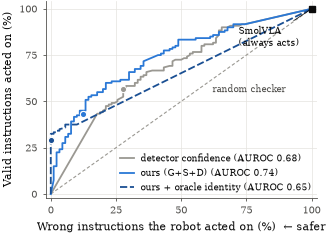

saved results/v4/paper_figures/fig_tradeoff.pdf / .png


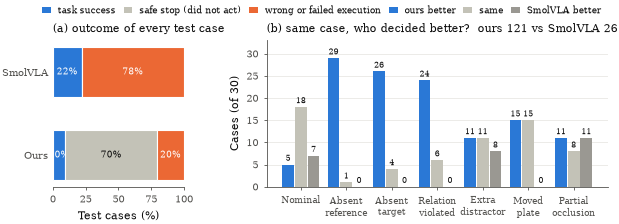

saved results/v4/paper_figures/fig_head_to_head.pdf / .png


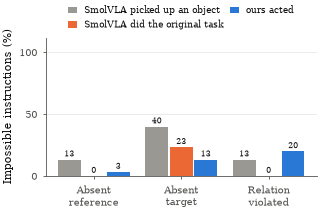

saved results/v4/paper_figures/fig_invalid_behaviour.pdf / .png


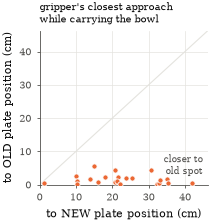

saved results/v4/paper_figures/fig_memorisation_scatter.pdf / .png


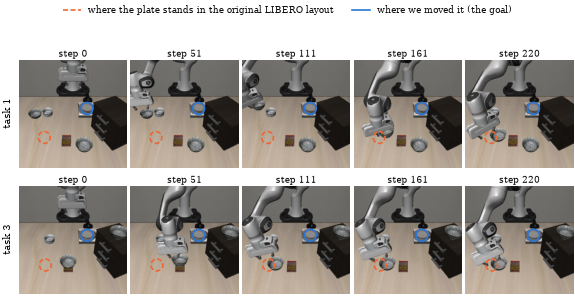

saved results/v4/paper_figures/fig_memorisation_frames.pdf / .png


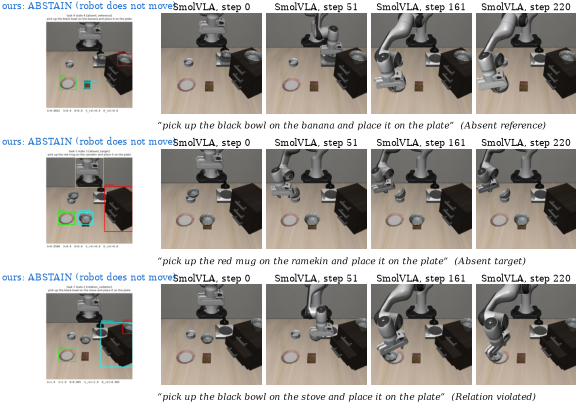

saved results/v4/paper_figures/fig_side_by_side.pdf / .png

ALL MAJOR RESULTS -> results/v5/tables | figures -> results/v4/paper_figures


In [ ]:
# %% CELL v5_major_results
# ============================================================================
# v5 · MAJOR RESULTS + FIGURES (seconds). Uses every file that exists; missing experiments are skipped.
#   (2) simple baselines: random checker, detector-confidence checker (tuned on development), oracle identity
#   (3) head-to-head on the SAME 210 test cases (success > safe stop > wrong/failed execution)
#   (7) task-level (cluster) bootstrap confidence intervals
#   + analysis of experiments 1, 4, 5 and the picture figures (6)
# Run the PAPER FIGURES cell once before this one (it sets the figure style).
# ============================================================================
assert "plot_main" in globals(), "Run the PAPER FIGURES cell first (it defines the figure style)."
V5_DIR = os.path.join(RESULTS_ROOT, "v5")
V5_TAB = os.path.join(V5_DIR, "tables")
FIG5 = os.path.join(V4_DIR, "paper_figures")
FRAMES_DIR = os.path.join(V5_DIR, "frames")
ORACLE_CSV = os.path.join(V5_DIR, "oracle_identity_test.csv")
MEMO_CSV = os.path.join(V5_DIR, "memorisation_test.csv")
os.makedirs(V5_TAB, exist_ok=True)
FROZEN = json.load(open(FROZEN_JSON))
FCFG = {**FROZEN, "weights": tuple(FROZEN["weights"]), "ramp": tuple(FROZEN["ramp"])}
bsm = base_success_map()
roll = (pd.read_csv(ROLL_CSV).drop_duplicates(["task_id", "state", "condition"], keep="last")
        if os.path.exists(ROLL_CSV) else pd.DataFrame(columns=ROLL_FIELDS))
rsm = {(int(r.task_id), int(r.state), r.condition): int(r.success) for r in roll.itertuples()}
dv, tv = load_verify("dev"), load_verify("test")

def attach(dec):
    dec = dec.copy()
    dec["smolvla_success"] = [bsm.get((int(r.task_id), int(r.state))) if r.kind == "clean"
                              else rsm.get((int(r.task_id), int(r.state), r.kind)) for r in dec.itertuples()]
    return dec

RANK = {"success": 2, "stop": 1, "bad": 0}
def outcome(valid, executed, s):
    """per case: 'success' (valid, acted, SmolVLA succeeded) | 'stop' (did not act) | 'bad' (acted on an invalid
    instruction, or acted on a valid one and failed)"""
    if not executed:
        return "stop"
    if valid == 0:
        return "bad"
    return None if s is None or s != s else ("success" if s == 1 else "bad")

def metrics(dec, name):
    inv, val = dec[dec.valid == 0], dec[dec.valid == 1]
    known = val[val.smolvla_success.notna()]
    cl = dec[(dec.kind == "clean") & dec.smolvla_success.notna()]
    outs = [outcome(r.valid, r.executed, r.smolvla_success) for r in dec.itertuples()]
    outs = [o for o in outs if o is not None]
    acc = known[known.executed == 1]
    k = int(inv.executed.sum())
    return {"method": name, "wrong-instruction acted %": pct(inv.executed.mean()), "95% CI": wilson(k, len(inv)),
            "valid acted %": pct(val.executed.mean()), "nominal success %": pct((cl.executed * cl.smolvla_success).mean()),
            "success when acting (valid) %": pct(acc.smolvla_success.mean()) if len(acc) else float("nan"),
            "bad executions % (all 210)": pct(np.mean([o == "bad" for o in outs])),
            "AUROC": round(auroc(dec[dec.valid == 1].C, dec[dec.valid == 0].C), 3) if "C" in dec else float("nan")}

test = attach(decide_all(tv, FCFG))
smol = test.copy(); smol["executed"] = 1; smol["C"] = 1.0
rows = [metrics(smol, "SmolVLA (no checker)")]

# ---------- (2a) random checker with the SAME acceptance rate as ours ----------
a = float(test[test.valid == 1].executed.mean())
rng = np.random.default_rng(0)
rnd_rows = []
for rep in range(2000):
    d = smol.drop(columns=["C"]); d["executed"] = (rng.random(len(d)) < a).astype(int)
    rnd_rows.append(metrics(d, "random"))
rnd = pd.DataFrame(rnd_rows)
rows.append({"method": f"Random checker (acts {100 * a:.0f}% of the time)",
             "wrong-instruction acted %": round(rnd["wrong-instruction acted %"].mean(), 1),
             "95% CI": (round(rnd["wrong-instruction acted %"].quantile(0.025), 1), round(rnd["wrong-instruction acted %"].quantile(0.975), 1)),
             "valid acted %": round(rnd["valid acted %"].mean(), 1), "nominal success %": round(rnd["nominal success %"].mean(), 1),
             "success when acting (valid) %": round(rnd["success when acting (valid) %"].mean(), 1),
             "bad executions % (all 210)": round(rnd["bad executions % (all 210)"].mean(), 1), "AUROC": 0.5})

# ---------- (2b) detector-confidence checker: C = G only, threshold chosen on DEVELOPMENT with the same objective ----------
def g_only(t):
    return {**FCFG, "weights": (1.0, 0.0, 0.0, 0.0), "high": t, "low": t, "mid_rule": False}
best_t, best_j = None, -9
for t in np.round(np.arange(0.05, 0.96, 0.025), 3):
    j = summarize(decide_all(dv, g_only(t)))["J"]
    if j > best_j + 1e-9:
        best_t, best_j = float(t), j
det = attach(decide_all(tv, g_only(best_t)))
rows.append(metrics(det, f"Detector-confidence checker (threshold {best_t:.3f}, tuned on dev)"))
rows.append(metrics(test, "Ours (G+S+D, frozen)"))

# ---------- (1) oracle object identity ----------
orc = None
if os.path.exists(ORACLE_CSV):
    o = pd.read_csv(ORACLE_CSV).drop_duplicates(["task_id", "state", "kind"], keep="last")
    if len(o) == len(tv):
        orc = attach(decide_all(o, FCFG))
        rows.append(metrics(orc, "Ours + oracle object identity (upper bound)"))
    else:
        print(f"oracle sweep incomplete ({len(o)}/{len(tv)}) - run the oracle cell to the end")
base_tab = pd.DataFrame(rows)
print("TABLE A - comparison with simple checkers (test set, N = 210; 90 wrong / 120 valid instructions)")
print(base_tab.to_string(index=False))
base_tab.to_csv(os.path.join(V5_TAB, "tableA_baselines.csv"), index=False)
_inv = test[test.valid == 0][["task_id", "state", "kind", "executed"]].merge(
    det[det.valid == 0][["task_id", "state", "kind", "executed"]], on=["task_id", "state", "kind"], suffixes=("_ours", "_det"))
_b = int(((_inv.executed_det == 1) & (_inv.executed_ours == 0)).sum()); _c = int(((_inv.executed_det == 0) & (_inv.executed_ours == 1)).sum())
print(f"ours vs detector-confidence checker on the wrong instructions: ours stops {_b} it lets through, it stops {_c} ours lets "
      f"through -> exact McNemar p = {mcnemar_exact(_b, _c):.2e}")
if orc is not None:
    print("oracle identity - grounding check: right bowl selected (valid):",
          pct(pd.to_numeric(orc[orc.valid == 1].right_target_0, errors="coerce").mean()), "%")

# ---------- (3) head-to-head on the same cases ----------
h = []
for r in test.itertuples():
    s = r.smolvla_success
    so, oo = outcome(r.valid, 1, s), outcome(r.valid, r.executed, s)
    if so is None or oo is None:
        continue
    h.append({"kind": r.kind, "task_id": int(r.task_id), "smolvla": so, "ours": oo,
              "result": "ours better" if RANK[oo] > RANK[so] else ("SmolVLA better" if RANK[oo] < RANK[so] else "same")})
h = pd.DataFrame(h)
hh = pd.crosstab(h.kind, h.result).reindex(KINDS).fillna(0).astype(int)
for c_ in ["ours better", "same", "SmolVLA better"]:
    if c_ not in hh:
        hh[c_] = 0
hh = hh[["ours better", "same", "SmolVLA better"]]
hh.loc["ALL"] = hh.sum()
nb_, nw_ = int(hh.loc["ALL", "ours better"]), int(hh.loc["ALL", "SmolVLA better"])
print("\nTABLE B - head-to-head on the same test cases (ranking: success > safe stop > wrong/failed execution)")
print(hh.to_string())
print(f"ours better in {nb_} cases, SmolVLA better in {nw_} -> exact sign test p = {mcnemar_exact(nb_, nw_):.2e}")
dist = pd.DataFrame({m: h[m].value_counts(normalize=True).reindex(["success", "stop", "bad"]).fillna(0) * 100
                     for m in ("smolvla", "ours")}).round(1)
print("\noutcome distribution over all test cases (%):"); print(dist.to_string())
hh.to_csv(os.path.join(V5_TAB, "tableB_head_to_head.csv")); dist.to_csv(os.path.join(V5_TAB, "tableB_outcomes.csv"))

# ---------- (7) task-level bootstrap (resample the 10 tasks) ----------
def boot(df, fn, B=3000, seed=0):
    rg = np.random.default_rng(seed); tasks = df.task_id.unique(); out = []
    groups = {t: df[df.task_id == t] for t in tasks}
    for _ in range(B):
        d = pd.concat([groups[t] for t in rg.choice(tasks, len(tasks))])
        v = fn(d)
        if v == v:
            out.append(v)
    return (round(float(np.percentile(out, 2.5)), 1), round(float(np.percentile(out, 97.5)), 1))
bt = pd.DataFrame([
    {"quantity": "ours: wrong-instruction acted %", "value": pct(test[test.valid == 0].executed.mean()),
     "95% CI (task bootstrap)": boot(test, lambda d: 100 * d[d.valid == 0].executed.mean())},
    {"quantity": "detector checker: wrong-instruction acted %", "value": pct(det[det.valid == 0].executed.mean()),
     "95% CI (task bootstrap)": boot(det, lambda d: 100 * d[d.valid == 0].executed.mean())},
    {"quantity": "ours: valid acted %", "value": pct(test[test.valid == 1].executed.mean()),
     "95% CI (task bootstrap)": boot(test, lambda d: 100 * d[d.valid == 1].executed.mean())},
    {"quantity": "bad executions: SmolVLA %", "value": dist.loc["bad", "smolvla"],
     "95% CI (task bootstrap)": boot(h, lambda d: 100 * (d.smolvla == "bad").mean())},
    {"quantity": "bad executions: ours %", "value": dist.loc["bad", "ours"],
     "95% CI (task bootstrap)": boot(h, lambda d: 100 * (d.ours == "bad").mean())},
    {"quantity": "AUROC of C", "value": round(auroc(test[test.valid == 1].C, test[test.valid == 0].C), 3),
     "95% CI (task bootstrap)": boot(test, lambda d: auroc(d[d.valid == 1].C, d[d.valid == 0].C) if d.valid.nunique() == 2 else float("nan"), B=500)}])
print("\nTABLE C - task-level bootstrap confidence intervals (10 tasks resampled)")
print(bt.to_string(index=False)); bt.to_csv(os.path.join(V5_TAB, "tableC_bootstrap.csv"), index=False)

# ---------- (4) what SmolVLA does with impossible instructions ----------
invr = roll[roll.condition.isin(INVALID_KINDS_V4)]
inv_tab = None
if len(invr):
    rows4 = []
    for kind in INVALID_KINDS_V4:
        g = invr[invr.condition == kind]
        if not len(g):
            continue
        lifted = [int(r.target_lifted == 1 or (isinstance(r.other_lifted, str) and len(r.other_lifted) > 0)) for r in g.itertuples()]
        same = [int(bsm.get((int(r.task_id), int(r.state))) == int(r.success)) for r in g.itertuples()]
        rows4.append({"condition": kind, "N": len(g), "picked up an object %": pct(np.mean(lifted)),
                      "carried out the ORIGINAL task %": pct(g.success.mean()),
                      "same outcome as with the correct instruction %": pct(np.mean(same)),
                      "ours acted %": pct(test[test.kind == kind].executed.mean())})
    inv_tab = pd.DataFrame(rows4)
    print("\nTABLE D - SmolVLA's physical behaviour on impossible instructions (test)")
    print(inv_tab.to_string(index=False)); inv_tab.to_csv(os.path.join(V5_TAB, "tableD_invalid_behaviour.csv"), index=False)
else:
    print("\n(experiment 4 not run yet - no invalid-instruction rollouts found)")

# ---------- (5) memorisation ----------
memo = None
if os.path.exists(MEMO_CSV):
    memo = pd.read_csv(MEMO_CSV).drop_duplicates(["task_id", "state"], keep="last")
    lm = memo[memo.target_lifted == 1].dropna(subset=["eef_min_old_cm", "eef_min_new_cm"])
    print(f"\nMEMORISATION (moved plate, {len(memo)} episodes; plate moved by {memo.plate_shift_cm.median():.0f} cm median)")
    print(f"  success: {int(memo.success.sum())}/{len(memo)} | bowl lifted in {len(lm)}")
    if len(lm):
        print(f"  after lifting, gripper came within 5 cm of the plate's OLD spot in {int((lm.eef_min_old_cm < 5).sum())}/{len(lm)}, "
              f"of its NEW spot in {int((lm.eef_min_new_cm < 5).sum())}/{len(lm)}")
        print(f"  closer to the OLD spot than to the NEW one in {int((lm.eef_min_old_cm < lm.eef_min_new_cm).sum())}/{len(lm)} "
              f"(exact sign test p = {mcnemar_exact(int((lm.eef_min_old_cm < lm.eef_min_new_cm).sum()), int((lm.eef_min_old_cm > lm.eef_min_new_cm).sum())):.2e})")
        print(f"  median closest approach: old spot {lm.eef_min_old_cm.median():.1f} cm vs new plate {lm.eef_min_new_cm.median():.1f} cm")
    memo.to_csv(os.path.join(V5_TAB, "tableE_memorisation.csv"), index=False)
else:
    print("\n(experiment 5 not run yet)")

# ---------- official evaluation (experiment 8) ----------
_off = os.path.join(V5_DIR, "official_eval_summary.json")
if os.path.exists(_off):
    print("\nOFFICIAL LeRobot evaluation of the same checkpoint:", json.load(open(_off)))

# ============================ FIGURES ============================
# Fig T - safety/usefulness trade-off: every single-threshold operating point for ours, the detector checker and the oracle
def _curve(dec):
    pos, neg = dec[dec.valid == 1].C.values, dec[dec.valid == 0].C.values
    th = np.r_[np.inf, np.unique(np.r_[pos, neg])[::-1], -np.inf]
    return [100 * (neg >= t).mean() for t in th], [100 * (pos >= t).mean() for t in th]
fig, ax = plt.subplots(figsize=(COL_W, 2.55))
ax.plot([0, 100], [0, 100], color=C_SMOL, lw=0.8, ls=(0, (3, 2)), zorder=2)
ax.text(62, 55, "random checker", rotation=0, fontsize=6.5, color=C_MUTED)
for dec, lab, col, ls in [(det, "detector confidence", C_SMOL, "-"), (test, "ours (G+S+D)", C_OURS, "-")] + \
                         ([(orc, "ours + oracle identity", "#1a4f93", (0, (4, 1.5)))] if orc is not None else []):
    x, y = _curve(dec)
    ax.plot(x, y, color=col, lw=1.3, ls=ls, label=f"{lab} (AUROC {auroc(dec[dec.valid == 1].C, dec[dec.valid == 0].C):.2f})", zorder=3)
    ax.plot([100 * dec[dec.valid == 0].executed.mean()], [100 * dec[dec.valid == 1].executed.mean()], "o", ms=4.5,
            color=col, mec="#ffffff", mew=0.8, zorder=5)
ax.plot([100], [100], "s", ms=5, color="#0b0b0b", zorder=5)
ax.annotate("SmolVLA\n(always acts)", (100, 100), xytext=(72, 80), fontsize=6.5, arrowprops={"arrowstyle": "-", "lw": 0.5})
ax.set_xlim(-2, 102); ax.set_ylim(-2, 104); ax.set_xticks([0, 25, 50, 75, 100]); ax.set_yticks([0, 25, 50, 75, 100])
ax.set_xlabel("Wrong instructions the robot acted on (%)  ← safer"); ax.set_ylabel("Valid instructions acted on (%)")
ax.legend(loc="lower right", fontsize=6.3, handlelength=1.6, borderaxespad=0.2)
_grid(ax, "both")
_save(fig, FIG5, "fig_tradeoff")

# Fig H - outcome distribution SmolVLA vs ours (same 210 cases) + head-to-head per condition
fig, (a1, a2) = plt.subplots(1, 2, figsize=(FULL_W, 1.9), gridspec_kw={"width_ratios": [1, 2.6], "wspace": 0.35})
cols3 = {"success": C_OURS, "stop": "#c3c2b7", "bad": C_DET}
names3 = {"success": "task success", "stop": "safe stop (did not act)", "bad": "wrong or failed execution"}
for yy, m, lab in ((1, "smolvla", "SmolVLA"), (0, "ours", "Ours")):
    left = 0
    for k_ in ("success", "stop", "bad"):
        v = dist.loc[k_, m]
        a1.barh(yy, v, 0.6, left=left, color=cols3[k_], edgecolor="#ffffff", lw=0.8, zorder=3)
        if v >= 8:
            a1.text(left + v / 2, yy, f"{v:.0f}%", ha="center", va="center", fontsize=6.5,
                    color="#0b0b0b" if k_ == "stop" else "#ffffff")
        left += v
a1.set_yticks([1, 0]); a1.set_yticklabels(["SmolVLA", "Ours"]); a1.set_xlim(0, 100); a1.set_xlabel("Test cases (%)")
a1.spines["left"].set_visible(False); a1.tick_params(axis="y", length=0)
a1.set_title("(a) outcome of every test case", loc="left")
hp = hh.drop(index="ALL")
x = np.arange(len(hp)); w = 0.26
for j, (c_, col) in enumerate([("ours better", C_OURS), ("same", "#c3c2b7"), ("SmolVLA better", C_SMOL)]):
    bb = a2.bar(x + (j - 1) * (w + 0.02), hp[c_].values, w, color=col, label=c_, zorder=3)
    _bar_labels(a2, bb, hp[c_].values, dy=0.4, size=6)
a2.set_xticks(x); a2.set_xticklabels([COND[k] for k in hp.index], fontsize=6.5)
a2.set_ylabel("Cases (of 30)"); a2.set_ylim(0, 33)
a2.set_title(f"(b) same case, who decided better?  ours {nb_} vs SmolVLA {nw_}", loc="left")
_grid(a2)
fig.legend(handles=[Patch(facecolor=cols3[k], label=names3[k]) for k in ("success", "stop", "bad")] +
                   [Patch(facecolor=C_OURS, label="ours better"), Patch(facecolor="#c3c2b7", label="same"),
                    Patch(facecolor=C_SMOL, label="SmolVLA better")],
           loc="lower center", bbox_to_anchor=(0.5, 0.97), ncol=6, fontsize=6.3, handlelength=1.0, columnspacing=0.9)
_save(fig, FIG5, "fig_head_to_head")

# Fig D - SmolVLA on impossible instructions
if inv_tab is not None and len(inv_tab):
    fig, ax = plt.subplots(figsize=(COL_W, 1.8))
    x = np.arange(len(inv_tab)); w = 0.26
    for j, (c_, col, lab) in enumerate([("picked up an object %", C_SMOL, "SmolVLA picked up an object"),
                                        ("carried out the ORIGINAL task %", C_DET, "SmolVLA did the original task"),
                                        ("ours acted %", C_OURS, "ours acted")]):
        bb = ax.bar(x + (j - 1) * (w + 0.02), inv_tab[c_].values, w, color=col, label=lab, zorder=3)
        _bar_labels(ax, bb, inv_tab[c_].values, dy=1.0, size=6)
    ax.set_xticks(x); ax.set_xticklabels([COND[k] for k in inv_tab.condition]); ax.set_ylim(0, 112)
    ax.set_yticks([0, 50, 100]); ax.set_ylabel("Impossible instructions (%)")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=6.3, handlelength=1.0, columnspacing=0.8)
    _grid(ax)
    _save(fig, FIG5, "fig_invalid_behaviour")

# Fig M - memorisation scatter + frames
if memo is not None:
    lm = memo[memo.target_lifted == 1].dropna(subset=["eef_min_old_cm", "eef_min_new_cm"])
    if len(lm):
        fig, ax = plt.subplots(figsize=(COL_W * 0.62, 2.0))
        lim = max(lm.eef_min_old_cm.max(), lm.eef_min_new_cm.max()) * 1.08 + 1
        ax.plot([0, lim], [0, lim], color=C_GRID, lw=0.8, zorder=1)
        ax.scatter(lm.eef_min_new_cm, lm.eef_min_old_cm, s=14, color=C_DET, edgecolor="#ffffff", lw=0.6, zorder=3)
        ax.set_xlim(0, lim); ax.set_ylim(0, lim)
        ax.set_xlabel("to NEW plate position (cm)"); ax.set_ylabel("to OLD plate position (cm)")
        ax.set_title("gripper's closest approach\nwhile carrying the bowl", loc="left", fontsize=7)
        ax.text(lim * 0.97, lim * 0.05, "closer to\nold spot", ha="right", va="bottom", fontsize=6.3, color=C_MUTED)
        _grid(ax, "both")
        _save(fig, FIG5, "fig_memorisation_scatter")
    pick = memo[(memo.target_lifted == 1)].copy()
    if len(pick):
        pick["margin"] = pick.eef_min_new_cm - pick.eef_min_old_cm
        pick = pick.sort_values("margin", ascending=False).drop_duplicates("task_id").head(2)
        fig, axs = plt.subplots(len(pick), 5, figsize=(FULL_W, 1.55 * len(pick)), squeeze=False)
        for rr, r in enumerate(pick.itertuples()):
            z = np.load(os.path.join(FRAMES_DIR, f"memo_t{int(r.task_id)}_s{int(r.state)}.npz"))
            for cc in range(5):
                ax = axs[rr, cc]
                if cc < len(z["frames"]):
                    ax.imshow(z["frames"][cc])
                    uo, un = z["uv_old"], z["uv_new"]
                    if np.all(np.isfinite(uo)):
                        ax.add_patch(plt.Circle((uo[0], uo[1]), 14, fill=False, ec=C_DET, lw=1.2, ls=(0, (3, 1.5))))
                    if np.all(np.isfinite(un)):
                        ax.add_patch(plt.Circle((un[0], un[1]), 14, fill=False, ec=C_OURS, lw=1.2))
                    ax.set_title(f"step {int(z['steps'][cc])}", fontsize=6.5, pad=2)
                ax.axis("off")
            axs[rr, 0].text(-0.06, 0.5, f"task {int(r.task_id)}", transform=axs[rr, 0].transAxes, rotation=90,
                            ha="right", va="center", fontsize=7)
        fig.legend(handles=[plt.Line2D([], [], color=C_DET, ls=(0, (3, 1.5)), lw=1.2, label="where the plate stands in the original LIBERO layout"),
                            plt.Line2D([], [], color=C_OURS, lw=1.2, label="where we moved it (the goal)")],
                   loc="lower center", bbox_to_anchor=(0.5, 0.99), ncol=2, fontsize=6.5)
        plt.subplots_adjust(wspace=0.03, hspace=0.12)
        _save(fig, FIG5, "fig_memorisation_frames")

# Fig Q - same scene, same impossible instruction: ours stops / SmolVLA acts
pairs = [k for k in INVALID_KINDS_V4 if os.path.exists(os.path.join(FRAMES_DIR, f"pair_{k}.npz"))]
if pairs:
    fig, axs = plt.subplots(len(pairs), 5, figsize=(FULL_W, 1.62 * len(pairs)), squeeze=False,
                            gridspec_kw={"width_ratios": [1.35, 1, 1, 1, 1]})
    for rr, k in enumerate(pairs):
        z = np.load(os.path.join(FRAMES_DIR, f"pair_{k}.npz"))
        tag, instr = str(z["caption"]).split("|", 1)
        t_, s_ = tag[1:].split("_s")
        panel = os.path.join(V4_QUAL, f"t{t_}_s{s_}_{k}.png")
        ax = axs[rr, 0]
        if os.path.exists(panel):
            ax.imshow(plt.imread(panel))
        ax.axis("off")
        ax.set_title("ours: ABSTAIN (robot does not move)", fontsize=6.5, pad=2, color=C_OURS)
        fr = z["frames"]
        for cc in range(1, 5):
            ax = axs[rr, cc]
            i_ = min(len(fr) - 1, int(round((cc - 1) * (len(fr) - 1) / 3)))
            ax.imshow(fr[i_]); ax.axis("off")
            ax.set_title(f"SmolVLA, step {int(z['steps'][i_])}", fontsize=6.5, pad=2)
        axs[rr, 1].text(-0.04, -0.08, f"“{instr}”  ({COND[k].replace(chr(10), ' ')})", transform=axs[rr, 1].transAxes,
                        fontsize=6.5, va="top", style="italic")
    plt.subplots_adjust(wspace=0.04, hspace=0.32)
    _save(fig, FIG5, "fig_side_by_side")

print("\nALL MAJOR RESULTS ->", V5_TAB, "| figures ->", FIG5)